In [3]:
import os
import h5py
import glob
import numpy as np
import pandas as pd
import math
from scipy.integrate import quad
from astropy import constants as const
from scipy.interpolate import interp1d
from scipy.interpolate import CubicSpline

from scipy.signal import savgol_filter

import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 200
mpl.rcParams['savefig.dpi'] = 300

import matplotlib.pyplot as plt
plt.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
    "font.size": 14,
})
import cmasher as cmr
import gc
gc.collect()

import matplotlib.gridspec as gridspec
from matplotlib.colors import TwoSlopeNorm
import re

In [ ]:
# Power spectra: mode-weighted rebinning of the C output (PS_NNN.out).
# PS_21cm_mpi.c / PS_3cm_mpi.c write 2000 log bins in k; at k <~ 0.3 h/cMpc each non-empty bin is a single
# |n|^2 shell (~10-40 modes), so one bin scatters by 10-20%. load_ps (every cell below) passes its output through rebin_ps:
# Delta^2 = sum_i n_i Delta^2_i / sum_i n_i over the fine bins i in each wide bin (the mean over all modes in the
# wide bin, relative error ~ 1/sqrt(N_modes)), so the curves need no further smoothing. ps_at reads Delta^2 at one k.
PS_BINS_PER_DECADE = 10

def rebin_ps(k, delta2, nmodes, per_decade=None):
    """Mode-weighted Delta^2 in log-k bins with edges at 10**(j / per_decade), the same edges for every file.
    k of a bin = exp(mode-weighted mean of ln k). Returns k, Delta^2, nmodes of the non-empty bins."""
    per_decade = PS_BINS_PER_DECADE if per_decade is None else per_decade
    k, delta2, nmodes = (np.asarray(a, dtype=float) for a in (k, delta2, nmodes))
    ok = nmodes > 0
    k, delta2, nmodes = k[ok], delta2[ok], nmodes[ok]
    idx = np.floor(np.log10(k) * per_decade).astype(int)
    idx -= idx.min()
    n = np.bincount(idx, nmodes)
    use = n > 0
    k_bin = np.exp(np.bincount(idx, nmodes * np.log(k))[use] / n[use])
    d2_bin = np.bincount(idx, nmodes * delta2)[use] / n[use]
    return k_bin, d2_bin, n[use]

def ps_at(k0, k, delta2):
    """Delta^2 at k0 by log-log interpolation of a (rebinned) spectrum; nan outside its k range"""
    return 10**np.interp(np.log10(k0), np.log10(k), np.log10(delta2), left=np.nan, right=np.nan)

## NEW 21 cm T_b

In [4]:
import re
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

from matplotlib.colors import SymLogNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.patheffects as path_effects
from matplotlib.colors import TwoSlopeNorm



In [3]:
with h5py.File("/orcd/data/mvogelsb/004/chcho/compute_J_alpha_He/Tb_He/RIN_514.hdf5", "r") as f:
    data = (f["/rin"][:])
    print(f"min:  {data.min():.4e}")
    print(f"max:  {data.max():.4e}")
    print(f"mean: {data.mean():.4e}")
    print(f"shape: {data.shape}")

min:  4.1039e-07
max:  2.5301e+00
mean: 1.1554e-02
shape: (640, 640, 640)


In [4]:
with h5py.File("/orcd/data/mvogelsb/004/chcho/compute_J_alpha_He/Tb_He/RIN_209.hdf5", "r") as f:
    data = (f["/rin"][:])
    print(f"min:  {data.min():.4e}")
    print(f"max:  {data.max():.4e}")
    print(f"mean: {data.mean():.4e}")
    print(f"shape: {data.shape}")

min:  9.6107e-08
max:  5.9710e+00
mean: 2.4690e-02
shape: (640, 640, 640)


In [5]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
import numpy as np

managua_cmap = sns.color_palette("managua", as_cmap=True)

# Sample managua from 0→1 for positive side
pos_colors = managua_cmap(np.linspace(0, 1, 128))

# Get the exact color at managua's zero point (first color)
color_at_zero = pos_colors[0]

# Negative part: red (at -10) → exact managua zero color (at 0)
neg_colors = LinearSegmentedColormap.from_list(
    "neg", ["red", color_at_zero]
)(np.linspace(0, 1, 128))

# Stitch
custom_cmap = LinearSegmentedColormap.from_list(
    "custom", np.vstack([neg_colors, pos_colors])
)

norm = TwoSlopeNorm(vmin=-10, vcenter=0, vmax=100)

from matplotlib.colors import LogNorm, Normalize

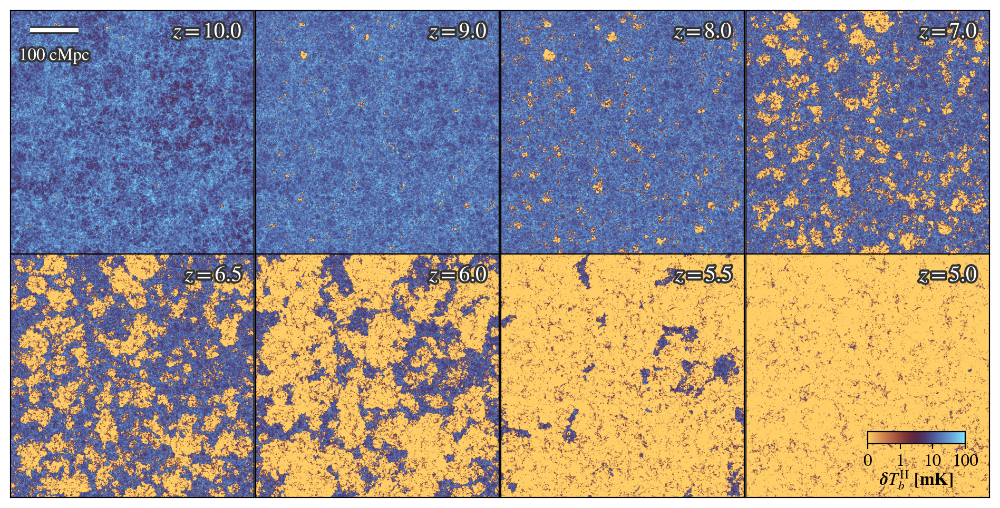

In [6]:
from matplotlib.ticker import LogLocator, NullLocator


# =====================================
# Helper
# =====================================

def get_redshift(ps_file):
    with open(ps_file) as f:
        return float(f.readline().strip())

#/orcd/data/mvogelsb/004/chcho/compute_J_alpha_H/Tb_H
# =====================================
# Input files
# =====================================
snaps = [156, 181, 209, 255, 289, 325, 364, 406]

base_path = "/orcd/data/mvogelsb/004/chcho/cell_by_cell/hydrogen/Tb_H"
files = [f"{base_path}/RIN_{snap}.hdf5" for snap in snaps]

# =====================================
# Figure layout
# =====================================

fig = plt.figure(figsize=(12, 6))

gs = gridspec.GridSpec(
    2, 4,
    wspace=0,
    hspace=0
)

axes = [
    fig.add_subplot(gs[i, j])
    for i in range(2)
    for j in range(4)
]


# =====================================
# Color normalization
# Tb map with symlog including zero
# =====================================
"""
norm = SymLogNorm(
    linthresh=1,
    linscale=1,
    vmin=-10,
    vmax=100,
    base=10
)
"""
#norm = TwoSlopeNorm(vmin=-10, vcenter=0, vmax=100)
#norm = TwoSlopeNorm(vmin=-10, vcenter=0, vmax=50)
#norm = TwoSlopeNorm(vmin=-0.1, vcenter=10, vmax=100)
#norm = TwoSlopeNorm(vmin=0, vcenter=10, vmax=100)
norm = LogNorm(vmin=0.1, vmax=100)

# =====================================
# Load + plot hydrogen Tb maps
# =====================================

for i, snap in enumerate(snaps):

    hdf5_file = (
        f"/orcd/data/mvogelsb/004/chcho/compute_J_alpha_H/Tb_H/RIN_{snap:03d}.hdf5"
    )

    PS_file = (
        f"/orcd/data/mvogelsb/004/chcho/compute_J_alpha_H/Tb_H/PS_{snap:03d}.out"
    )

    z = get_redshift(PS_file)

    # ---------------------------------
    # Load cube
    # ---------------------------------

    with h5py.File(hdf5_file, "r") as f:
        Tb_cube = f["/rin"][:]

    N = Tb_cube.shape[0]

    # Mid-plane slice
    Tb = Tb_cube[:, :, N // 2]

    ax = axes[i]

    im = ax.imshow(
        Tb.T,
        origin="lower",
        cmap=sns.color_palette(
            "managua", # #"rocket_r, "winter", "berlin", "managua"
            as_cmap=True
        ),
        norm=norm,
        extent=[0, 500, 0, 500]
    )


    im = ax.imshow(
        np.where(Tb > 0, Tb, np.nan).T,
        origin="lower",
        cmap=sns.color_palette("managua", as_cmap=True),
        norm=norm,
        extent=[0, 500, 0, 500]
    )
    
    # Negative overlay — dark spots
    ax.imshow(
        np.where(Tb < 0, Tb, np.nan).T,
        origin="lower",
        cmap="Reds_r",
        norm=Normalize(vmin=-10, vmax=0),
        extent=[0, 500, 0, 500]
    )
   
#    im = ax.imshow(
#        Tb.T,
#        origin="lower",
#        cmap=cmr.pride,   # pass directly, no sns.color_palette wrapper
#        norm=norm,
#        extent=[0, 500, 0, 500]
#    )

    # Remove ticks
    ax.set_xticks([])
    ax.set_yticks([])

    # =================================
    # Better redshift label
    # (from new figure style)
    # =================================

    txt = ax.text(
        0.95,
        0.95,
        fr"$z = {z:.1f}$",
        transform=ax.transAxes,
        color="white",
        fontsize=15,
        ha="right",
        va="top"
    )

    txt.set_path_effects([
        path_effects.Stroke(
            linewidth=3,
            foreground="0.2"
        ),
        path_effects.Normal()
    ])


# =====================================
# Inset colorbar + scale bar
# in last panel
# =====================================

ax_last = axes[-1]

cax = inset_axes(
    ax_last,
    width="40%",
    height="5%",
    loc="lower right",
    #borderpad=2.7
    bbox_to_anchor=(-0.1, 0.22, 1, 1),   # (x, y, w, h) in axes fraction; increase x to move right
    bbox_transform=ax_last.transAxes,
    borderpad=0
)

# THIS creates the actual bar
cbar = fig.colorbar(
    im,
    cax=cax,
    orientation="horizontal"
)

# Tick locations

cbar.set_ticks([0.1, 1, 10, 100])
cbar.set_ticklabels(["0", "1", "10", "100"])
cbar.ax.xaxis.set_minor_locator(NullLocator())  # remove minor ticks
#ticks
#cbar.set_ticks([-10, -1, 0, 1, 10, 100])
#cbar.set_ticks([-10, 0, 50, 100])
#cbar.set_ticklabels(["-10", "-1", "0", "1", "10", "100"])


# =====================================
# Make colorbar texts visible using
# outline (same style as redshift text)
# =====================================



# -------------------------------------
# Tick labels with outline
# -------------------------------------

#cbar.ax.tick_params(
#    labelsize=12,
#    colors="black"   # white text
#)

cbar.ax.tick_params(labelsize=12, colors="black")


#for tick in cbar.ax.get_xticklabels():
#    tick.set_color("black")
#    tick.set_fontweight("bold")
    
#for tick in cbar.ax.get_xticklabels():
#    tick.set_color("white")
#    tick.set_path_effects([
#        path_effects.Stroke(linewidth=1.5, foreground="black"),
#        path_effects.Normal()
#    ])

#for tick in cbar.ax.get_xticklabels():
#    tick.set_color("white")
#    tick.set_path_effects([
#        path_effects.Stroke(
#            linewidth=2,
#            foreground="black"
#        ),
#        path_effects.Normal()
#    ])

# -------------------------------------
# TOP label = physical scale bar
# -------------------------------------

#title = cbar.ax.set_title(
#    "200 cMpc",
#    fontsize=11,
#    pad=4,
#    color="black"
#)

#title.set_path_effects([
#    path_effects.Stroke(
#        linewidth=2,
#        foreground="black"
#    ),
#    path_effects.Normal()
#])

# -------------------------------------
# BOTTOM label = Tb quantity
# -------------------------------------


label = cbar.ax.text(
    0.5, -2.1,
    #r"$\delta T_b^{\mathrm{H}}\ [{\rm mK}]$",
    r"$\boldsymbol{\delta T_b^{\mathrm{H}}}\ \mathbf{[mK]}$",
    transform=cbar.ax.transAxes,
    fontsize=12, ha="center", va="top",
    color="black"
)
#label.set_path_effects([
#    path_effects.Stroke(linewidth=2.0, foreground="black"),
#    path_effects.Normal()
#])

#label.set_path_effects([
#    path_effects.Stroke(
#        linewidth=2,
#        foreground="black"
#    ),
#    path_effects.Normal()
#])
# =====================================
# Scale bar: 100 cMpc on the upper-left panel
# =====================================

ax_first = axes[0]

# Bar geometry in data coordinates (extent is 0-500 cMpc)
bar_length = 100.0          # cMpc
x0 = 40                     # left end of bar (data units)
y0 = 460                    # height of bar (near top)

# The bar itself
ax_first.plot(
    [x0, x0 + bar_length],
    [y0, y0],
    color="white",
    lw=3,
    solid_capstyle="butt",
    path_effects=[
        path_effects.Stroke(linewidth=5, foreground="0.15"),
        path_effects.Normal()
    ]
)

# Label above the bar
lbl = ax_first.text(
    x0 + bar_length / 2,
    y0 - 35,
    r"$100\ \mathrm{cMpc}$",
    color="white",
    fontsize=12,
    ha="center",
    va="top"
)
lbl.set_path_effects([
    path_effects.Stroke(linewidth=3, foreground="0.2"),
    path_effects.Normal()
])
# =====================================
# Final layout
# =====================================

#plt.tight_layout()

# plt.savefig(
#     "Tb_H_map_symlog_inset.png",
#     dpi=300,
#     bbox_inches="tight"
# )

plt.show()

snap 156  z=10.01  x_HI percentiles [1,25,50,75,99]: 4.72e-02  1.00e+00  1.00e+00  1.00e+00  1.00e+00
snap 181  z= 9.01  x_HI percentiles [1,25,50,75,99]: 1.78e-03  9.94e-01  1.00e+00  1.00e+00  1.00e+00
snap 209  z= 8.00  x_HI percentiles [1,25,50,75,99]: 1.93e-04  6.87e-01  1.00e+00  1.00e+00  1.00e+00
snap 255  z= 7.01  x_HI percentiles [1,25,50,75,99]: 5.16e-05  9.79e-03  7.90e-01  1.00e+00  1.00e+00
snap 289  z= 6.50  x_HI percentiles [1,25,50,75,99]: 2.46e-05  2.54e-04  8.20e-02  9.88e-01  1.00e+00
snap 325  z= 6.00  x_HI percentiles [1,25,50,75,99]: 1.00e-05  5.08e-05  1.62e-04  1.17e-01  1.00e+00
snap 364  z= 5.50  x_HI percentiles [1,25,50,75,99]: 5.01e-06  1.65e-05  3.07e-05  6.82e-05  1.00e+00
snap 406  z= 5.00  x_HI percentiles [1,25,50,75,99]: 2.21e-06  6.56e-06  1.07e-05  1.85e-05  1.61e-04


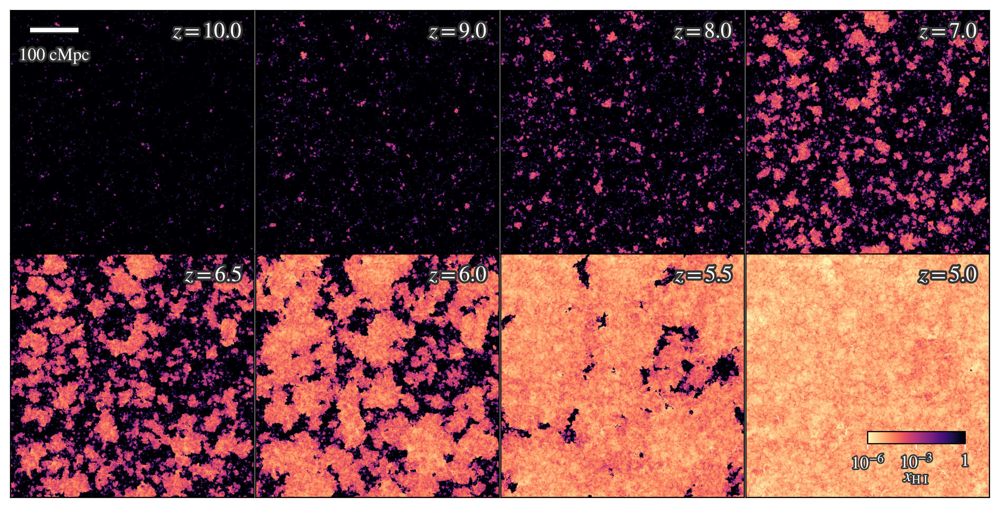

In [13]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LogNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.patheffects as path_effects
# -----------------------------------
# Color scale
#
# We plot the neutral hydrogen fraction, x_HI (= 1 - x_HII), on a
# standard logarithmic color scale (LogNorm) from 1 (neutral) down to
# 10^-N_DECADES (highly ionized). This is the same transform as
# before, just expressed as what it actually is -- a log scale on
# x_HI -- instead of a custom forward/inverse pair on x_HII. Pixel
# colors are identical either way; this version is the one you can
# describe in a methods section without hand-waving: "colored by the
# neutral hydrogen fraction, x_HI, on a base-10 log scale from 1 to
# 1e-N_DECADES."
#
# CMAP is reversed ("magma_r") because we're now coloring by the
# NEUTRAL fraction: low neutral fraction (= highly ionized) should be
# bright, high neutral fraction (= neutral gas) should be black --
# magma_r puts black at its high end, matching that.
#
# N_DECADES: how many decades of neutral fraction to resolve before
# saturating.
#   4 -> saturates at 1-x_HII = 1e-4  (x_HII = 0.9999)
#   6 -> saturates at 1-x_HII = 1e-6  (x_HII = 0.999999)  [confirmed good]
# -----------------------------------
N_DECADES = 6
CMAP      = "magma_r"
VERBOSE   = True   # print percentiles of (1 - x_HII) so N_DECADES can be tuned
EPS = 10.0 ** (-N_DECADES)
norm = LogNorm(vmin=EPS, vmax=1.0)
# ---- real log-scale colorbar ticks, in neutral-fraction (x_HI) units ----
CBAR_TICKS  = [1e-6, 1e-3, 1.0]
CBAR_LABELS = [r"$10^{-6}$", r"$10^{-3}$", "1"]
# -----------------------------------
# Helper
# -----------------------------------
def get_redshift(ps_file):
    with open(ps_file) as f:
        return float(f.readline().strip())
def hdf5_path(snap):
    if snap <= 428:
        run = "Flagship_new"
    else:
        run = "Flagship_below_z_4p75_new"
    return (
        f"/orcd/data/mvogelsb/005/mkilab001/"
        f"mvogelsblab003/Lab/Thesan-XL/"
        f"{run}/postprocessing/ren_640/"
        f"HII_VolumeFraction/"
        f"HII_VolumeFraction_{snap:03d}.hdf5"
    )
# -----------------------------------
# SNAPSHOTS
# -----------------------------------
snaps = [156, 181, 209, 255, 289, 325, 364, 406]
# -----------------------------------
# FIGURE LAYOUT
# -----------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2, 4,
    wspace=0,
    hspace=0
)
axes = [
    fig.add_subplot(gs[i, j])
    for i in range(2)
    for j in range(4)
]
# -----------------------------------
# LOAD + PLOT HII MAPS
# -----------------------------------
for i, snap in enumerate(snaps):
    PS_file = (
        f"/orcd/data/mvogelsb/004/chcho/compute_J_alpha_H/Tb_H/PS_{snap:03d}.out"
    )
    z = get_redshift(PS_file)
    # ---- mid-plane slice, read directly (no full cube in memory) ----
    with h5py.File(hdf5_path(snap), "r") as f:
        dset = f["/HII_VolumeFraction"]
        N = dset.shape[0]
        f_HII = dset[:, :, N // 2]
    f_HII_plot = np.clip(f_HII, 0.0, 1.0)
    x_HI = np.clip(1.0 - f_HII_plot, EPS, 1.0)  # the field actually plotted
    if VERBOSE:
        p = np.percentile(x_HI, [1, 25, 50, 75, 99])
        print(
            f"snap {snap:3d}  z={z:5.2f}  "
            f"x_HI percentiles [1,25,50,75,99]: "
            + "  ".join(f"{v:.2e}" for v in p),
            flush=True
        )
    # ---- plot ----
    ax = axes[i]
    im = ax.imshow(
        x_HI.T,
        origin="lower",
        cmap=CMAP,
        norm=norm,
        extent=[0, 500, 0, 500]
    )
    ax.set_xticks([])
    ax.set_yticks([])
    # ---- redshift label ----
    txt = ax.text(
        0.95,
        0.95,
        fr"$z = {z:.1f}$",
        transform=ax.transAxes,
        color="white",
        fontsize=15,
        ha="right",
        va="top"
    )
    txt.set_path_effects([
        path_effects.Stroke(
            linewidth=3,
            foreground="0.2"
        ),
        path_effects.Normal()
    ])
# -----------------------------------
# Inset colorbar inside last panel
# -----------------------------------
ax_last = axes[-1]
cax = inset_axes(
    ax_last,
    width="40%",
    height="5%",
    loc="lower right",
    bbox_to_anchor=(-0.1, 0.22, 1, 1),   # (x, y, w, h) in axes fraction
    bbox_transform=ax_last.transAxes,
    borderpad=0
)
cbar = fig.colorbar(
    im,
    cax=cax,
    orientation="horizontal"
)
cbar.set_ticks(CBAR_TICKS)
cbar.set_ticklabels(CBAR_LABELS)
cbar.ax.tick_params(labelsize=12, colors="white")
cbar.ax.xaxis.set_minor_locator(plt.NullLocator())
for t in cbar.ax.get_xticklabels():
    t.set_path_effects([
        path_effects.Stroke(linewidth=2, foreground="0.2"),
        path_effects.Normal()
    ])
# BOTTOM label = neutral hydrogen fraction, x_HI (= 1 - x_HII)
label = cbar.ax.text(
    0.5,
    -2.1,
    r"$x_{\mathrm{H \ I}}$",
    transform=cbar.ax.transAxes,
    fontsize=12,
    ha="center",
    va="top",
    color="white"
)
label.set_path_effects([
    path_effects.Stroke(linewidth=2, foreground="0.2"),
    path_effects.Normal()
])
# -----------------------------------
# Scale bar: 100 cMpc on the upper-left panel
# -----------------------------------
ax_first = axes[0]
bar_length = 100.0          # cMpc
x0 = 40                     # left end of bar (data units)
y0 = 460                    # height of bar (near top)
ax_first.plot(
    [x0, x0 + bar_length],
    [y0, y0],
    color="white",
    lw=3,
    solid_capstyle="butt",
    path_effects=[
        path_effects.Stroke(linewidth=5, foreground="0.15"),
        path_effects.Normal()
    ]
)
lbl = ax_first.text(
    x0 + bar_length / 2,
    y0 - 35,
    r"$100\ \mathrm{cMpc}$",
    color="white",
    fontsize=12,
    ha="center",
    va="top"
)
lbl.set_path_effects([
    path_effects.Stroke(linewidth=3, foreground="0.2"),
    path_effects.Normal()
])
# -----------------------------------
# SAVE + SHOW
# -----------------------------------
# plt.savefig(
#     "f_HII_map_log_inset.png",
#     dpi=300,
#     bbox_inches="tight"
# )
plt.show()

## NEW Helium T_b

In [14]:
with h5py.File("/orcd/data/mvogelsb/004/chcho/compute_J_alpha_He/Tb_He/RIN_705.hdf5", "r") as f:
    data = (f["/rin"][:])
    print(f"min:  {data.min():.4e}")
    print(f"max:  {data.max():.4e}")
    print(f"mean: {data.mean():.4e}")
    print(f"shape: {data.shape}")

min:  3.5329e-08
max:  1.1314e+00
mean: 5.2666e-04
shape: (640, 640, 640)


In [15]:
with h5py.File("/orcd/data/mvogelsb/004/chcho/compute_J_alpha_He/Tb_He/RIN_705.hdf5", "r") as f:
    data = (f["/rin"][:])
    print(f"min:  {data.min():.4e}")
    print(f"max:  {data.max():.4e}")
    print(f"mean: {data.mean():.4e}")
    print(f"shape: {data.shape}")

min:  3.5329e-08
max:  1.1314e+00
mean: 5.2666e-04
shape: (640, 640, 640)


In [16]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import re

from matplotlib.colors import SymLogNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.patheffects as path_effects
from matplotlib.colors import LogNorm


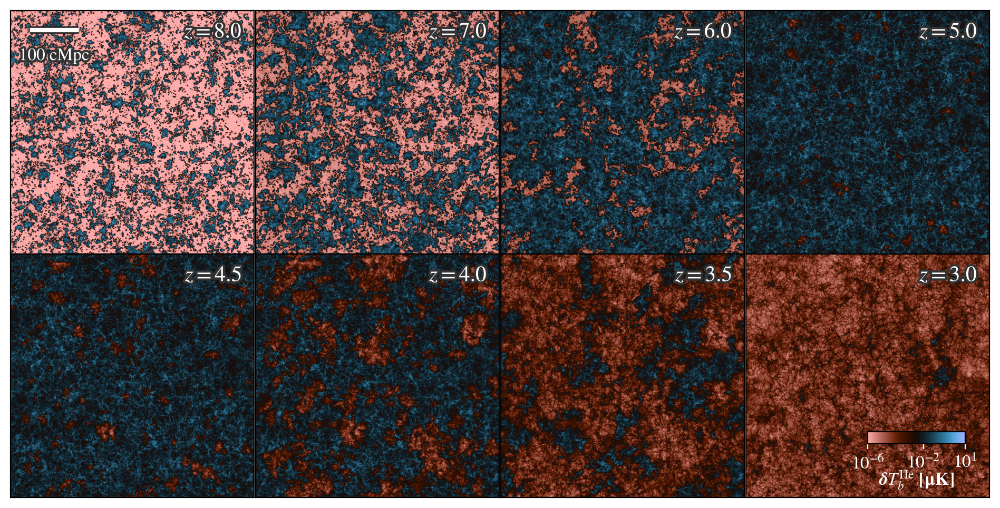

In [21]:

# =====================================
# Helper
# =====================================

def get_redshift(ps_file):
    with open(ps_file) as f:
        return float(f.readline().strip())


# =====================================
# Input files
# =====================================
snaps = [209, 255, 325, 406, 452, 501, 582, 705]

base_path = "/orcd/data/mvogelsb/004/chcho/cell_by_cell/helium/Tb_He"
files = [f"{base_path}/RIN_{snap}.hdf5" for snap in snaps]

#ps_files = [f"./TS_TK/He/Tb/PS_Tb_He_{snap}.out" for snap in snaps]

# =====================================
# Figure layout (better publication size)
# =====================================

fig = plt.figure(figsize=(12, 6))

gs = gridspec.GridSpec(
    2, 4,
    wspace=0,
    hspace=0
)

axes = [
    fig.add_subplot(gs[i, j])
    for i in range(2)
    for j in range(4)
]


# =====================================
# Color normalization
# =====================================
"""
norm = SymLogNorm(
    linthresh=.1,
    linscale=1,
    vmin=0,
    vmax=10, #vmax=100,
    base=10
)
"""


norm = LogNorm(vmin=1e-6, vmax=10)

# =====================================
# Load + plot helium Tb maps
# =====================================

for i, snap in enumerate(snaps):

    hdf5_file = (
        f"/orcd/data/mvogelsb/004/chcho/compute_J_alpha_He/Tb_He/"
        f"RIN_{snap:03d}.hdf5"
    )

    PS_file = (
        f"/orcd/data/mvogelsb/004/chcho/PS_21cm/All_include/He/Tb/"
        f"PS_{snap:03d}.out"
    )

    z = get_redshift(PS_file)

    # ---------------------------------
    # Load cube
    # ---------------------------------

    with h5py.File(hdf5_file, "r") as f:
        Tb_cube = f["/rin"][:]

    N = Tb_cube.shape[0]
    Tb = Tb_cube[:, :, N // 2]

    ax = axes[i]

    im = ax.imshow(
        Tb.T,
        origin="lower",
        cmap=sns.color_palette(
            "berlin_r",
            as_cmap=True
        ),
        norm=norm,
        extent=[0, 500, 0, 500]
    )


    #    im = ax.imshow(
#        Tb.T,
#        origin="lower",
#        cmap=sns.color_palette(
#            "seismic", #"rocket_r, "winter", "berlin", "managua"
#            as_cmap=True
#        ),
#        norm=norm,
#        extent=[0, 500, 0, 500]
#    )

    # remove ticks
    ax.set_xticks([])
    ax.set_yticks([])

    # =================================
    # Redshift label with boundary
    # =================================

    txt = ax.text(
        0.95,
        0.95,
        fr"$z = {z:.1f}$",
        transform=ax.transAxes,
        color="white",
        fontsize=15,
        ha="right",
        va="top"
    )

    txt.set_path_effects([
        path_effects.Stroke(
            linewidth=3,
            foreground="0.2"
        ),
        path_effects.Normal()
    ])


# =====================================
# Inset colorbar + scale bar
# in last panel
# =====================================

ax_last = axes[-1]

cax = inset_axes(
    ax_last,
    width="40%",
    height="5%",
    loc="lower right",
    #borderpad=2.7
    bbox_to_anchor=(-0.1, 0.22, 1, 1),   # (x, y, w, h) in axes fraction; increase x to move right
    bbox_transform=ax_last.transAxes,
    borderpad=0
)

# THIS creates the actual bar
cbar = fig.colorbar(
    im,
    cax=cax,
    orientation="horizontal"
)

cbar.set_ticks([1e-6, 1e-2, 1e1])
cbar.set_ticklabels([r"$10^{-6}$",r"$10^{-2}$", r"$10^{1}$"])
"""

# Tick locations
cbar.set_ticks([
    0,
    1,
    10,
    100
])

cbar.set_ticklabels([
    "0",
    "1",
    "10",
    "100"
])
"""

# =====================================
# Make colorbar texts visible using
# outline (same style as redshift text)
# =====================================

import matplotlib.patheffects as path_effects

# -------------------------------------
# Tick labels with outline
# -------------------------------------

cbar.ax.tick_params(
    labelsize=12,
    colors="white"   # white text
)

#for tick in cbar.ax.get_xticklabels():
#    tick.set_color("white")
#    tick.set_path_effects([
#        path_effects.Stroke(
#            linewidth=2,
#            foreground="black"
#        ),
#        path_effects.Normal()
#    ])

# -------------------------------------
# TOP label = physical scale bar
# -------------------------------------


#title.set_path_effects([
#    path_effects.Stroke(
#        linewidth=2,
#        foreground="black"
#    ),
#    path_effects.Normal()
#])

# -------------------------------------
# BOTTOM label = Tb quantity
# -------------------------------------

label = cbar.ax.text(
    0.5,
    -2.1,
    r"$\boldsymbol{\delta T_b^{\mathrm{He}}}\ \mathbf{[\mu K]}$",
    transform=cbar.ax.transAxes,
    fontsize=12,
    ha="center",
    va="top",
    color="white"
)



ax_first = axes[0]

# Bar geometry in data coordinates (extent is 0-500 cMpc)
bar_length = 100.0          # cMpc
x0 = 40                     # left end of bar (data units)
y0 = 460                    # height of bar (near top)

# The bar itself
ax_first.plot(
    [x0, x0 + bar_length],
    [y0, y0],
    color="white",
    lw=3,
    solid_capstyle="butt",
    path_effects=[
        path_effects.Stroke(linewidth=5, foreground="0.15"),
        path_effects.Normal()
    ]
)

# Label above the bar
lbl = ax_first.text(
    x0 + bar_length / 2,
    y0 - 35,
    r"$100\ \mathrm{cMpc}$",
    color="white",
    fontsize=12,
    ha="center",
    va="top"
)
lbl.set_path_effects([
    path_effects.Stroke(linewidth=3, foreground="0.2"),
    path_effects.Normal()
])

# =====================================
# Final layout
# =====================================

# plt.savefig(
#     "Tb_He_map_inset.png",
#     dpi=300,
#     bbox_inches="tight"
# )

plt.show()

---

## Previous code


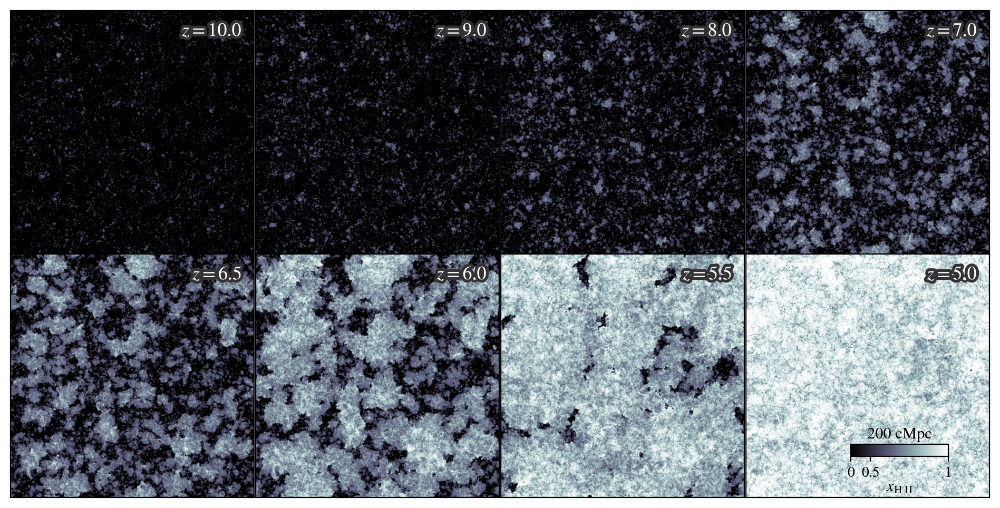

In [7]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.patheffects as path_effects


# -----------------------------------
# Helper
# -----------------------------------

def get_redshift(ps_file):
    with open(ps_file) as f:
        return float(f.readline().strip())


# -----------------------------------
# SNAPSHOTS
# -----------------------------------

snaps = [156, 181, 209, 255, 289, 325, 364, 406]


# -----------------------------------
# FIGURE LAYOUT
# -----------------------------------

fig = plt.figure(figsize=(12, 6))

gs = gridspec.GridSpec(
    2, 4,
    wspace=0,
    hspace=0
)

axes = [
    fig.add_subplot(gs[i, j])
    for i in range(2)
    for j in range(4)
]


# -----------------------------------
# LOG SCALE SETTINGS
# -----------------------------------

# avoid log10(0)
floor = 1e-2

# colorbar range: log10(x_HII)
#norm = Normalize(
#    vmin=-2,
#    vmax=1
#)

from matplotlib.colors import PowerNorm

#norm = PowerNorm(gamma=0.3, vmin=0, vmax=1)

from matplotlib.colors import FuncNorm

all_vals = []
for snap in snaps:
    if snap <= 428:
        hdf5_file = (
            f"/orcd/data/mvogelsb/005/mkilab001/"
            f"mvogelsblab003/Lab/Thesan-XL/"
            f"Flagship_new/postprocessing/ren_640/"
            f"HII_VolumeFraction/"
            f"HII_VolumeFraction_{snap:03d}.hdf5"
        )
    else:
        hdf5_file = (
            f"/orcd/data/mvogelsb/005/mkilab001/"
            f"mvogelsblab003/Lab/Thesan-XL/"
            f"Flagship_below_z_4p75_new/postprocessing/ren_640/"
            f"HII_VolumeFraction/"
            f"HII_VolumeFraction_{snap:03d}.hdf5"
        )

    with h5py.File(hdf5_file, "r") as f:
        data = f["/HII_VolumeFraction"][:]
    all_vals.append(data[data > 1e-3].ravel())

all_vals = np.sort(np.concatenate(all_vals))
cdf = np.linspace(0, 1, len(all_vals))

def forward(x): return np.interp(x, all_vals, cdf)
def inverse(y): return np.interp(y, cdf, all_vals)

norm = FuncNorm((forward, inverse), vmin=1e-3, vmax=1)
# And plot the raw fraction, not log

# -----------------------------------
# LOAD + PLOT HII MAPS
# -----------------------------------

for i, snap in enumerate(snaps):

    # -----------------------------------
    # File paths
    # -----------------------------------

    if snap <= 428:
        hdf5_file = (
            f"/orcd/data/mvogelsb/005/mkilab001/"
            f"mvogelsblab003/Lab/Thesan-XL/"
            f"Flagship_new/postprocessing/ren_640/"
            f"HII_VolumeFraction/"
            f"HII_VolumeFraction_{snap:03d}.hdf5"
        )
    else:
        hdf5_file = (
            f"/orcd/data/mvogelsb/005/mkilab001/"
            f"mvogelsblab003/Lab/Thesan-XL/"
            f"Flagship_below_z_4p75_new/postprocessing/ren_640/"
            f"HII_VolumeFraction/"
            f"HII_VolumeFraction_{snap:03d}.hdf5"
        )

    PS_file = (
        f"/orcd/data/mvogelsb/004/chcho/compute_J_alpha_H/Tb_H/PS_{snap:03d}.out"
    )

    z = get_redshift(PS_file)

    # -----------------------------------
    # Load cube
    # -----------------------------------

    with h5py.File(hdf5_file, "r") as f:
        f_HII_cube = f["/HII_VolumeFraction"][:]

    # -----------------------------------
    # Mid-plane slice
    # -----------------------------------

    N = f_HII_cube.shape[0]
    f_HII = f_HII_cube[:, :, N // 2]

    # -----------------------------------
    # Convert to log10 scale
    # -----------------------------------

    #f_HII_plot = np.log10(
    #    np.clip(f_HII, floor, 1.0)
    #)
    f_HII_plot = np.clip(f_HII, 0, 1)

    # -----------------------------------
    # Plot
    # -----------------------------------

    ax = axes[i]

    im = ax.imshow(
        f_HII_plot.T,
        origin="lower",
        cmap="bone",
        norm=norm,
        extent=[0, 500, 0, 500]
    )

    # remove ticks
    ax.set_xticks([])
    ax.set_yticks([])

    # -----------------------------------
    # Redshift label with boundary
    # -----------------------------------

    txt = ax.text(
        0.95,
        0.95,
        fr"$z = {z:.1f}$",
        transform=ax.transAxes,
        color="white",
        fontsize=13,
        ha="right",
        va="top"
    )

    txt.set_path_effects([
        path_effects.Stroke(
            linewidth=4,
            foreground="0.2"
        ),
        path_effects.Normal()
    ])


# -----------------------------------
# Inset colorbar inside last panel
# -----------------------------------

ax_last = axes[-1]

cax = inset_axes(
    ax_last,
    width="40%",
    height="5%",
    loc="lower right",
    borderpad=2.0
)

cbar = fig.colorbar(
    im,
    cax=cax,
    orientation="horizontal"
)

cbar.set_ticks([1e-3, 0.5, 1.0])
cbar.set_ticklabels(["0", "0.5", "1"])
cbar.ax.tick_params(labelsize=10, colors="black")


# TOP label = physical scale
cbar.ax.set_title(
    "200 cMpc",
    fontsize=11,
    pad=4
)

# BOTTOM label = ionization fraction
cbar.ax.text(
    0.5,
    -2.0,
    r"$x_{\mathrm{H \ II}}$", #\log 
    transform=cbar.ax.transAxes,
    fontsize=11,
    ha="center",
    va="top",
    color="black"
)
# -----------------------------------
# SAVE + SHOW
# -----------------------------------

# plt.savefig(
#     "f_HII_map_log_inset.png",
#     dpi=300,
#     bbox_inches="tight"
# )

plt.show()

snap 156  z=10.01  (1-x_HII) percentiles [1,25,50,75,99]: 4.72e-02  1.00e+00  1.00e+00  1.00e+00  1.00e+00
snap 181  z= 9.01  (1-x_HII) percentiles [1,25,50,75,99]: 1.78e-03  9.94e-01  1.00e+00  1.00e+00  1.00e+00
snap 209  z= 8.00  (1-x_HII) percentiles [1,25,50,75,99]: 1.93e-04  6.87e-01  1.00e+00  1.00e+00  1.00e+00
snap 255  z= 7.01  (1-x_HII) percentiles [1,25,50,75,99]: 5.16e-05  9.79e-03  7.90e-01  1.00e+00  1.00e+00
snap 289  z= 6.50  (1-x_HII) percentiles [1,25,50,75,99]: 2.46e-05  2.54e-04  8.20e-02  9.88e-01  1.00e+00
snap 325  z= 6.00  (1-x_HII) percentiles [1,25,50,75,99]: 1.00e-05  5.08e-05  1.62e-04  1.17e-01  1.00e+00
snap 364  z= 5.50  (1-x_HII) percentiles [1,25,50,75,99]: 5.01e-06  1.65e-05  3.07e-05  6.82e-05  1.00e+00
snap 406  z= 5.00  (1-x_HII) percentiles [1,25,50,75,99]: 2.21e-06  6.56e-06  1.07e-05  1.85e-05  1.61e-04


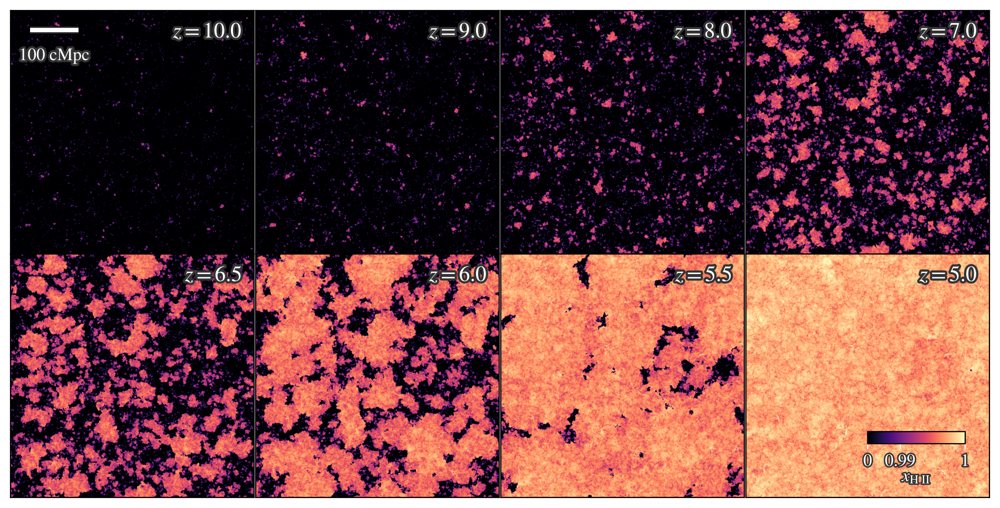

In [8]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import FuncNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.patheffects as path_effects


# -----------------------------------
# Color scale
#
# Field plotted is x_HII. Color is logarithmic in (1 - x_HII), so each
# factor of 10 closer to full ionization gets an equal slice of color.
#
# N_DECADES: how many decades above 0.9 to resolve.
#   4 -> saturates at 0.9999
#   6 -> saturates at 0.999999   (use when the distribution piles up at 1)
#
# CMAP: "bone" is a greyscale, which is why the old version looked
#   black and white. These have real hue variation:
#   "magma", "inferno", "viridis", "cividis", "plasma"
# -----------------------------------

N_DECADES = 6
CMAP      = "magma"

VERBOSE   = True   # print percentiles of (1 - x_HII) so N_DECADES can be tuned

EPS = 10.0 ** (-N_DECADES)


def forward(x):
    return -np.log10(np.clip(1.0 - x, EPS, 1.0))


def inverse(y):
    return 1.0 - 10.0 ** (-y)


norm = FuncNorm((forward, inverse), vmin=0.0, vmax=1.0)


# ---- colorbar ticks ----
# 0.999 sits at the midpoint of the bar when N_DECADES = 6

CBAR_TICKS  = [0.0, 0.99, 1.0]
CBAR_LABELS = ["0", "0.99", "1"]


# -----------------------------------
# Helper
# -----------------------------------

def get_redshift(ps_file):
    with open(ps_file) as f:
        return float(f.readline().strip())


def hdf5_path(snap):
    if snap <= 428:
        run = "Flagship_new"
    else:
        run = "Flagship_below_z_4p75_new"
    return (
        f"/orcd/data/mvogelsb/005/mkilab001/"
        f"mvogelsblab003/Lab/Thesan-XL/"
        f"{run}/postprocessing/ren_640/"
        f"HII_VolumeFraction/"
        f"HII_VolumeFraction_{snap:03d}.hdf5"
    )


# -----------------------------------
# SNAPSHOTS
# -----------------------------------

snaps = [156, 181, 209, 255, 289, 325, 364, 406]


# -----------------------------------
# FIGURE LAYOUT
# -----------------------------------

fig = plt.figure(figsize=(12, 6))

gs = gridspec.GridSpec(
    2, 4,
    wspace=0,
    hspace=0
)

axes = [
    fig.add_subplot(gs[i, j])
    for i in range(2)
    for j in range(4)
]


# -----------------------------------
# LOAD + PLOT HII MAPS
# -----------------------------------

for i, snap in enumerate(snaps):

    PS_file = (
        f"/orcd/data/mvogelsb/004/chcho/compute_J_alpha_H/Tb_H/PS_{snap:03d}.out"
    )

    z = get_redshift(PS_file)

    # ---- mid-plane slice, read directly (no full cube in memory) ----

    with h5py.File(hdf5_path(snap), "r") as f:
        dset = f["/HII_VolumeFraction"]
        N = dset.shape[0]
        f_HII = dset[:, :, N // 2]

    f_HII_plot = np.clip(f_HII, 0.0, 1.0)

    if VERBOSE:
        neutral = 1.0 - f_HII_plot
        p = np.percentile(neutral, [1, 25, 50, 75, 99])
        print(
            f"snap {snap:3d}  z={z:5.2f}  "
            f"(1-x_HII) percentiles [1,25,50,75,99]: "
            + "  ".join(f"{v:.2e}" for v in p),
            flush=True
        )

    # ---- plot ----

    ax = axes[i]

    im = ax.imshow(
        f_HII_plot.T,
        origin="lower",
        cmap=CMAP,
        norm=norm,
        extent=[0, 500, 0, 500]
    )

    ax.set_xticks([])
    ax.set_yticks([])

    # ---- redshift label ----

    txt = ax.text(
        0.95,
        0.95,
        fr"$z = {z:.1f}$",
        transform=ax.transAxes,
        color="white",
        fontsize=15,
        ha="right",
        va="top"
    )

    txt.set_path_effects([
        path_effects.Stroke(
            linewidth=3,
            foreground="0.2"
        ),
        path_effects.Normal()
    ])


# -----------------------------------
# Inset colorbar inside last panel
# -----------------------------------

ax_last = axes[-1]

cax = inset_axes(
    ax_last,
    width="40%",
    height="5%",
    loc="lower right",
    bbox_to_anchor=(-0.1, 0.22, 1, 1),   # (x, y, w, h) in axes fraction
    bbox_transform=ax_last.transAxes,
    borderpad=0
)

cbar = fig.colorbar(
    im,
    cax=cax,
    orientation="horizontal"
)

cbar.set_ticks(CBAR_TICKS)
cbar.set_ticklabels(CBAR_LABELS)
cbar.ax.tick_params(labelsize=12, colors="white")
cbar.ax.xaxis.set_minor_locator(plt.NullLocator())

for t in cbar.ax.get_xticklabels():
    t.set_path_effects([
        path_effects.Stroke(linewidth=2, foreground="0.2"),
        path_effects.Normal()
    ])

# BOTTOM label = ionization fraction
label = cbar.ax.text(
    0.5,
    -2.1,
    r"$x_{\mathrm{H \ II}}$",
    transform=cbar.ax.transAxes,
    fontsize=12,
    ha="center",
    va="top",
    color="white"
)
label.set_path_effects([
    path_effects.Stroke(linewidth=2, foreground="0.2"),
    path_effects.Normal()
])


# -----------------------------------
# Scale bar: 100 cMpc on the upper-left panel
# -----------------------------------

ax_first = axes[0]

bar_length = 100.0          # cMpc
x0 = 40                     # left end of bar (data units)
y0 = 460                    # height of bar (near top)

ax_first.plot(
    [x0, x0 + bar_length],
    [y0, y0],
    color="white",
    lw=3,
    solid_capstyle="butt",
    path_effects=[
        path_effects.Stroke(linewidth=5, foreground="0.15"),
        path_effects.Normal()
    ]
)

lbl = ax_first.text(
    x0 + bar_length / 2,
    y0 - 35,
    r"$100\ \mathrm{cMpc}$",
    color="white",
    fontsize=12,
    ha="center",
    va="top"
)
lbl.set_path_effects([
    path_effects.Stroke(linewidth=3, foreground="0.2"),
    path_effects.Normal()
])


# -----------------------------------
# SAVE + SHOW
# -----------------------------------

# plt.savefig(
#     "f_HII_map_log_inset.png",
#     dpi=300,
#     bbox_inches="tight"
# )

plt.show()

snap 156  z=10.01  (1-x_HII) percentiles [1,25,50,75,99]: 4.72e-02  1.00e+00  1.00e+00  1.00e+00  1.00e+00
snap 181  z= 9.01  (1-x_HII) percentiles [1,25,50,75,99]: 1.78e-03  9.94e-01  1.00e+00  1.00e+00  1.00e+00
snap 209  z= 8.00  (1-x_HII) percentiles [1,25,50,75,99]: 1.93e-04  6.87e-01  1.00e+00  1.00e+00  1.00e+00
snap 255  z= 7.01  (1-x_HII) percentiles [1,25,50,75,99]: 5.16e-05  9.79e-03  7.90e-01  1.00e+00  1.00e+00
snap 289  z= 6.50  (1-x_HII) percentiles [1,25,50,75,99]: 2.46e-05  2.54e-04  8.20e-02  9.88e-01  1.00e+00
snap 325  z= 6.00  (1-x_HII) percentiles [1,25,50,75,99]: 1.00e-05  5.08e-05  1.62e-04  1.17e-01  1.00e+00
snap 364  z= 5.50  (1-x_HII) percentiles [1,25,50,75,99]: 5.01e-06  1.65e-05  3.07e-05  6.82e-05  1.00e+00
snap 406  z= 5.00  (1-x_HII) percentiles [1,25,50,75,99]: 2.21e-06  6.56e-06  1.07e-05  1.85e-05  1.61e-04


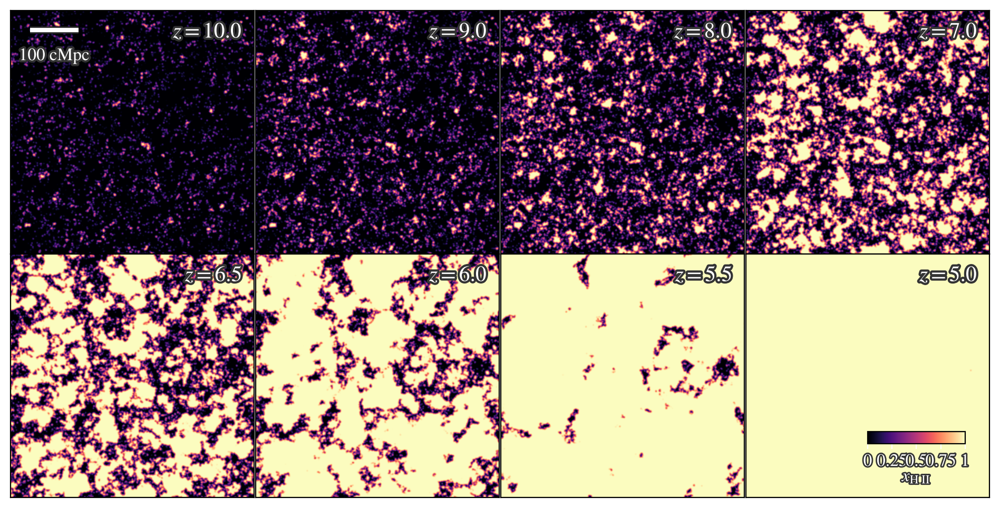

In [9]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import Normalize
from scipy.ndimage import gaussian_filter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.patheffects as path_effects
# -----------------------------------
# Color scale -- TRUE LINEAR on x_HII, full physical range.
#
# Honest limit of this choice: a linear scale cannot resolve the
# sub-percent residual structure (x_HII = 0.999 vs 0.999999) that the
# old log version showed inside "fully ionized" bubbles -- that's a
# hard consequence of linear color allocation, not a tuning problem,
# and no vmin/vmax window changes it.
#
# What linear CAN legitimately show is gradient at the ionization
# fronts themselves, if the front isn't a literal one-pixel step.
# SMOOTH_SIGMA (in pixels) blurs the DISPLAY copy of the field only --
# raw data and the printed percentiles below are untouched -- so each
# front renders as a soft ramp instead of a hard binary edge. This is
# the honest way to get visible gradient out of a strictly linear
# scale on an intrinsically near-binary field. Set to 0 to disable.
# -----------------------------------
CMAP         = "magma"
VMIN         = 0.0
VMAX         = 1.0
SMOOTH_SIGMA = 1.5   # pixels; try 0-3, larger = softer/more gradient, less sharp
VERBOSE      = True   # print percentiles of (1 - x_HII) as a sanity check
norm = Normalize(vmin=VMIN, vmax=VMAX)
# ---- colorbar ticks ----
CBAR_TICKS  = [0.0, 0.25, 0.5, 0.75, 1.0]
CBAR_LABELS = ["0", "0.25", "0.5", "0.75", "1"]
# -----------------------------------
# Helper
# -----------------------------------
def get_redshift(ps_file):
    with open(ps_file) as f:
        return float(f.readline().strip())
def hdf5_path(snap):
    if snap <= 428:
        run = "Flagship_new"
    else:
        run = "Flagship_below_z_4p75_new"
    return (
        f"/orcd/data/mvogelsb/005/mkilab001/"
        f"mvogelsblab003/Lab/Thesan-XL/"
        f"{run}/postprocessing/ren_640/"
        f"HII_VolumeFraction/"
        f"HII_VolumeFraction_{snap:03d}.hdf5"
    )
# -----------------------------------
# SNAPSHOTS
# -----------------------------------
snaps = [156, 181, 209, 255, 289, 325, 364, 406]
# -----------------------------------
# FIGURE LAYOUT
# -----------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2, 4,
    wspace=0,
    hspace=0
)
axes = [
    fig.add_subplot(gs[i, j])
    for i in range(2)
    for j in range(4)
]
# -----------------------------------
# LOAD + PLOT HII MAPS
# -----------------------------------
for i, snap in enumerate(snaps):
    PS_file = (
        f"/orcd/data/mvogelsb/004/chcho/compute_J_alpha_H/Tb_H/PS_{snap:03d}.out"
    )
    z = get_redshift(PS_file)
    # ---- mid-plane slice, read directly (no full cube in memory) ----
    with h5py.File(hdf5_path(snap), "r") as f:
        dset = f["/HII_VolumeFraction"]
        N = dset.shape[0]
        f_HII = dset[:, :, N // 2]
    f_HII_plot = np.clip(f_HII, 0.0, 1.0)
    if VERBOSE:
        neutral = 1.0 - f_HII_plot
        p = np.percentile(neutral, [1, 25, 50, 75, 99])
        print(
            f"snap {snap:3d}  z={z:5.2f}  "
            f"(1-x_HII) percentiles [1,25,50,75,99]: "
            + "  ".join(f"{v:.2e}" for v in p),
            flush=True
        )
    # ---- display copy: mild smoothing so fronts read as a linear
    #      gradient instead of a hard step; raw f_HII_plot above (and
    #      the percentiles) are unaffected ----
    f_HII_display = (
        gaussian_filter(f_HII_plot, sigma=SMOOTH_SIGMA)
        if SMOOTH_SIGMA > 0 else f_HII_plot
    )
    # ---- plot ----
    ax = axes[i]
    im = ax.imshow(
        f_HII_display.T,
        origin="lower",
        cmap=CMAP,
        norm=norm,
        extent=[0, 500, 0, 500]
    )
    ax.set_xticks([])
    ax.set_yticks([])
    # ---- redshift label ----
    txt = ax.text(
        0.95,
        0.95,
        fr"$z = {z:.1f}$",
        transform=ax.transAxes,
        color="white",
        fontsize=15,
        ha="right",
        va="top"
    )
    txt.set_path_effects([
        path_effects.Stroke(
            linewidth=3,
            foreground="0.2"
        ),
        path_effects.Normal()
    ])
# -----------------------------------
# Inset colorbar inside last panel
# -----------------------------------
ax_last = axes[-1]
cax = inset_axes(
    ax_last,
    width="40%",
    height="5%",
    loc="lower right",
    bbox_to_anchor=(-0.1, 0.22, 1, 1),   # (x, y, w, h) in axes fraction
    bbox_transform=ax_last.transAxes,
    borderpad=0
)
cbar = fig.colorbar(
    im,
    cax=cax,
    orientation="horizontal"
)
cbar.set_ticks(CBAR_TICKS)
cbar.set_ticklabels(CBAR_LABELS)
cbar.ax.tick_params(labelsize=12, colors="white")
cbar.ax.xaxis.set_minor_locator(plt.NullLocator())
for t in cbar.ax.get_xticklabels():
    t.set_path_effects([
        path_effects.Stroke(linewidth=2, foreground="0.2"),
        path_effects.Normal()
    ])
# BOTTOM label = ionization fraction
label = cbar.ax.text(
    0.5,
    -2.1,
    r"$x_{\mathrm{H \ II}}$",
    transform=cbar.ax.transAxes,
    fontsize=12,
    ha="center",
    va="top",
    color="white"
)
label.set_path_effects([
    path_effects.Stroke(linewidth=2, foreground="0.2"),
    path_effects.Normal()
])
# -----------------------------------
# Scale bar: 100 cMpc on the upper-left panel
# -----------------------------------
ax_first = axes[0]
bar_length = 100.0          # cMpc
x0 = 40                     # left end of bar (data units)
y0 = 460                    # height of bar (near top)
ax_first.plot(
    [x0, x0 + bar_length],
    [y0, y0],
    color="white",
    lw=3,
    solid_capstyle="butt",
    path_effects=[
        path_effects.Stroke(linewidth=5, foreground="0.15"),
        path_effects.Normal()
    ]
)
lbl = ax_first.text(
    x0 + bar_length / 2,
    y0 - 35,
    r"$100\ \mathrm{cMpc}$",
    color="white",
    fontsize=12,
    ha="center",
    va="top"
)
lbl.set_path_effects([
    path_effects.Stroke(linewidth=3, foreground="0.2"),
    path_effects.Normal()
])
# -----------------------------------
# SAVE + SHOW
# -----------------------------------
# plt.savefig(
#     "f_HII_map_log_inset.png",
#     dpi=300,
#     bbox_inches="tight"
# )
plt.show()

snap 156  z=10.01  (1-x_HII) percentiles [1,25,50,75,99]: 4.72e-02  1.00e+00  1.00e+00  1.00e+00  1.00e+00
snap 181  z= 9.01  (1-x_HII) percentiles [1,25,50,75,99]: 1.78e-03  9.94e-01  1.00e+00  1.00e+00  1.00e+00
snap 209  z= 8.00  (1-x_HII) percentiles [1,25,50,75,99]: 1.93e-04  6.87e-01  1.00e+00  1.00e+00  1.00e+00
snap 255  z= 7.01  (1-x_HII) percentiles [1,25,50,75,99]: 5.16e-05  9.79e-03  7.90e-01  1.00e+00  1.00e+00
snap 289  z= 6.50  (1-x_HII) percentiles [1,25,50,75,99]: 2.46e-05  2.54e-04  8.20e-02  9.88e-01  1.00e+00
snap 325  z= 6.00  (1-x_HII) percentiles [1,25,50,75,99]: 1.00e-05  5.08e-05  1.62e-04  1.17e-01  1.00e+00
snap 364  z= 5.50  (1-x_HII) percentiles [1,25,50,75,99]: 5.01e-06  1.65e-05  3.07e-05  6.82e-05  1.00e+00
snap 406  z= 5.00  (1-x_HII) percentiles [1,25,50,75,99]: 2.21e-06  6.56e-06  1.07e-05  1.85e-05  1.61e-04


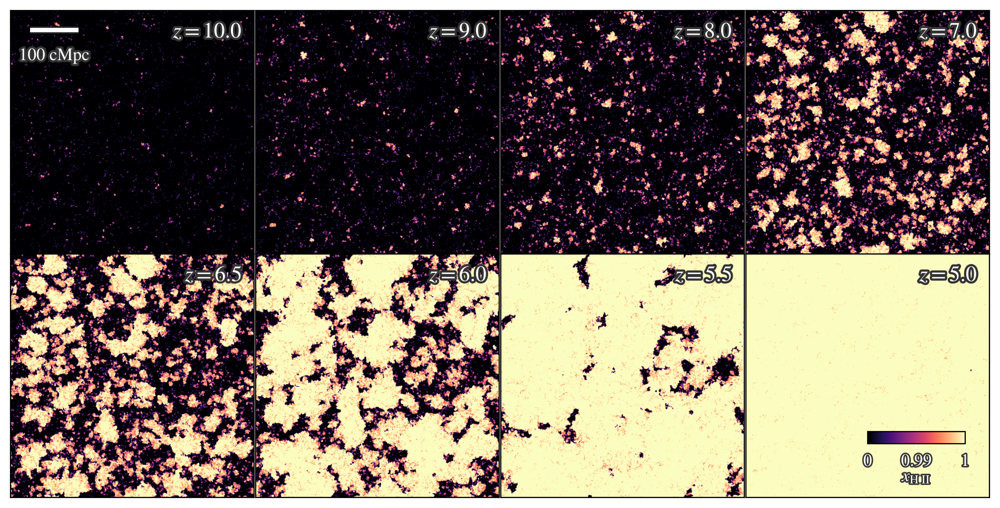

In [10]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import FuncNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.patheffects as path_effects
# -----------------------------------
# Color scale
#
# Field plotted is x_HII. Color is logarithmic in (1 - x_HII) over the
# range [1e-4, 1]: each factor-of-10 step closer to full ionization
# gets an equal slice of the colorbar, and it saturates at
# 1 - x_HII = 1e-4 (x_HII = 0.9999).
#
# N_DECADES is the range knob -- currently 4, i.e. [1e-4, 1]:
#   4 -> saturates at 1 - x_HII = 1e-4  (x_HII = 0.9999)   [current]
#   6 -> saturates at 1 - x_HII = 1e-6  (x_HII = 0.999999) [previous]
# Lower N_DECADES gives more contrast in the earlier/less-extreme
# panels at the cost of saturating the late-time bubble interiors
# sooner -- check the printed percentiles below: z=5.0's 99th
# percentile of (1-x_HII) is ~1.6e-4, so at N_DECADES=4 essentially
# all of that panel is already past saturation.
# -----------------------------------
N_DECADES = 4
CMAP      = "magma"
VERBOSE   = True   # print percentiles of (1 - x_HII) so N_DECADES can be tuned
EPS = 10.0 ** (-N_DECADES)
def forward(x):
    return -np.log10(np.clip(1.0 - x, EPS, 1.0))
def inverse(y):
    return 1.0 - 10.0 ** (-y)
norm = FuncNorm((forward, inverse), vmin=0.0, vmax=1.0)
# ---- colorbar ticks ----
CBAR_TICKS  = [0.0, 0.99, 1.0]
CBAR_LABELS = ["0", "0.99", "1"]
# -----------------------------------
# Helper
# -----------------------------------
def get_redshift(ps_file):
    with open(ps_file) as f:
        return float(f.readline().strip())
def hdf5_path(snap):
    if snap <= 428:
        run = "Flagship_new"
    else:
        run = "Flagship_below_z_4p75_new"
    return (
        f"/orcd/data/mvogelsb/005/mkilab001/"
        f"mvogelsblab003/Lab/Thesan-XL/"
        f"{run}/postprocessing/ren_640/"
        f"HII_VolumeFraction/"
        f"HII_VolumeFraction_{snap:03d}.hdf5"
    )
# -----------------------------------
# SNAPSHOTS
# -----------------------------------
snaps = [156, 181, 209, 255, 289, 325, 364, 406]
# -----------------------------------
# FIGURE LAYOUT
# -----------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2, 4,
    wspace=0,
    hspace=0
)
axes = [
    fig.add_subplot(gs[i, j])
    for i in range(2)
    for j in range(4)
]
# -----------------------------------
# LOAD + PLOT HII MAPS
# -----------------------------------
for i, snap in enumerate(snaps):
    PS_file = (
        f"/orcd/data/mvogelsb/004/chcho/compute_J_alpha_H/Tb_H/PS_{snap:03d}.out"
    )
    z = get_redshift(PS_file)
    # ---- mid-plane slice, read directly (no full cube in memory) ----
    with h5py.File(hdf5_path(snap), "r") as f:
        dset = f["/HII_VolumeFraction"]
        N = dset.shape[0]
        f_HII = dset[:, :, N // 2]
    f_HII_plot = np.clip(f_HII, 0.0, 1.0)
    if VERBOSE:
        neutral = 1.0 - f_HII_plot
        p = np.percentile(neutral, [1, 25, 50, 75, 99])
        print(
            f"snap {snap:3d}  z={z:5.2f}  "
            f"(1-x_HII) percentiles [1,25,50,75,99]: "
            + "  ".join(f"{v:.2e}" for v in p),
            flush=True
        )
    # ---- plot ----
    ax = axes[i]
    im = ax.imshow(
        f_HII_plot.T,
        origin="lower",
        cmap=CMAP,
        norm=norm,
        extent=[0, 500, 0, 500]
    )
    ax.set_xticks([])
    ax.set_yticks([])
    # ---- redshift label ----
    txt = ax.text(
        0.95,
        0.95,
        fr"$z = {z:.1f}$",
        transform=ax.transAxes,
        color="white",
        fontsize=15,
        ha="right",
        va="top"
    )
    txt.set_path_effects([
        path_effects.Stroke(
            linewidth=3,
            foreground="0.2"
        ),
        path_effects.Normal()
    ])
# -----------------------------------
# Inset colorbar inside last panel
# -----------------------------------
ax_last = axes[-1]
cax = inset_axes(
    ax_last,
    width="40%",
    height="5%",
    loc="lower right",
    bbox_to_anchor=(-0.1, 0.22, 1, 1),   # (x, y, w, h) in axes fraction
    bbox_transform=ax_last.transAxes,
    borderpad=0
)
cbar = fig.colorbar(
    im,
    cax=cax,
    orientation="horizontal"
)
cbar.set_ticks(CBAR_TICKS)
cbar.set_ticklabels(CBAR_LABELS)
cbar.ax.tick_params(labelsize=12, colors="white")
cbar.ax.xaxis.set_minor_locator(plt.NullLocator())
for t in cbar.ax.get_xticklabels():
    t.set_path_effects([
        path_effects.Stroke(linewidth=2, foreground="0.2"),
        path_effects.Normal()
    ])
# BOTTOM label = ionization fraction
label = cbar.ax.text(
    0.5,
    -2.1,
    r"$x_{\mathrm{H \ II}}$",
    transform=cbar.ax.transAxes,
    fontsize=12,
    ha="center",
    va="top",
    color="white"
)
label.set_path_effects([
    path_effects.Stroke(linewidth=2, foreground="0.2"),
    path_effects.Normal()
])
# -----------------------------------
# Scale bar: 100 cMpc on the upper-left panel
# -----------------------------------
ax_first = axes[0]
bar_length = 100.0          # cMpc
x0 = 40                     # left end of bar (data units)
y0 = 460                    # height of bar (near top)
ax_first.plot(
    [x0, x0 + bar_length],
    [y0, y0],
    color="white",
    lw=3,
    solid_capstyle="butt",
    path_effects=[
        path_effects.Stroke(linewidth=5, foreground="0.15"),
        path_effects.Normal()
    ]
)
lbl = ax_first.text(
    x0 + bar_length / 2,
    y0 - 35,
    r"$100\ \mathrm{cMpc}$",
    color="white",
    fontsize=12,
    ha="center",
    va="top"
)
lbl.set_path_effects([
    path_effects.Stroke(linewidth=3, foreground="0.2"),
    path_effects.Normal()
])
# -----------------------------------
# SAVE + SHOW
# -----------------------------------
# plt.savefig(
#     "f_HII_map_log_inset.png",
#     dpi=300,
#     bbox_inches="tight"
# )
plt.show()

snap 156  z=10.01  (1-x_HII) percentiles [1,25,50,75,99]: 4.72e-02  1.00e+00  1.00e+00  1.00e+00  1.00e+00
snap 181  z= 9.01  (1-x_HII) percentiles [1,25,50,75,99]: 1.78e-03  9.94e-01  1.00e+00  1.00e+00  1.00e+00
snap 209  z= 8.00  (1-x_HII) percentiles [1,25,50,75,99]: 1.93e-04  6.87e-01  1.00e+00  1.00e+00  1.00e+00
snap 255  z= 7.01  (1-x_HII) percentiles [1,25,50,75,99]: 5.16e-05  9.79e-03  7.90e-01  1.00e+00  1.00e+00
snap 289  z= 6.50  (1-x_HII) percentiles [1,25,50,75,99]: 2.46e-05  2.54e-04  8.20e-02  9.88e-01  1.00e+00
snap 325  z= 6.00  (1-x_HII) percentiles [1,25,50,75,99]: 1.00e-05  5.08e-05  1.62e-04  1.17e-01  1.00e+00
snap 364  z= 5.50  (1-x_HII) percentiles [1,25,50,75,99]: 5.01e-06  1.65e-05  3.07e-05  6.82e-05  1.00e+00
snap 406  z= 5.00  (1-x_HII) percentiles [1,25,50,75,99]: 2.21e-06  6.56e-06  1.07e-05  1.85e-05  1.61e-04


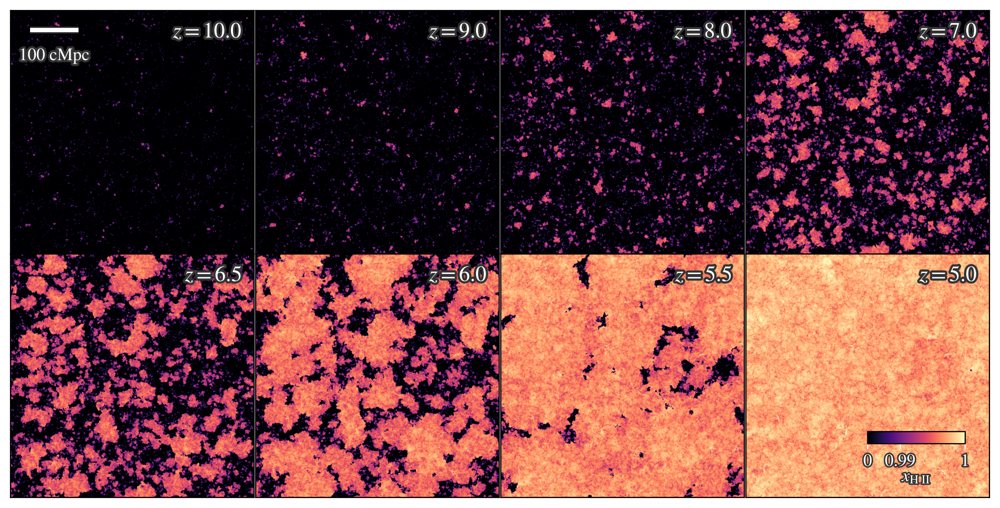

In [11]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import FuncNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.patheffects as path_effects
# -----------------------------------
# Color scale
#
# Field plotted is x_HII. Color is logarithmic in (1 - x_HII), so each
# factor of 10 closer to full ionization gets an equal slice of color.
# This is the construction that actually shows the evolution well --
# confirmed against the real data: at z=5.0 the whole box spans
# (1-x_HII) ~ 2e-6 to 1.6e-4, nearly two decades of real variation
# packed into a sliver of x_HII space that no linear or log(x) scale
# can see. -log10(1-x) is built to expand exactly that sliver.
#
# N_DECADES: how many decades above 0.9 to resolve.
#   4 -> saturates at 0.9999
#   6 -> saturates at 0.999999   (use when the distribution piles up at 1)
#
# CMAP: "bone" is a greyscale, which is why the old version looked
#   black and white. These have real hue variation:
#   "magma", "inferno", "viridis", "cividis", "plasma"
# -----------------------------------
N_DECADES = 6
CMAP      = "magma"
VERBOSE   = True   # print percentiles of (1 - x_HII) so N_DECADES can be tuned
EPS = 10.0 ** (-N_DECADES)
def forward(x):
    return -np.log10(np.clip(1.0 - x, EPS, 1.0))
def inverse(y):
    return 1.0 - 10.0 ** (-y)
norm = FuncNorm((forward, inverse), vmin=0.0, vmax=1.0)
# ---- colorbar ticks ----
# 0.999 sits at the midpoint of the bar when N_DECADES = 6
CBAR_TICKS  = [0.0, 0.99, 1.0]
CBAR_LABELS = ["0", "0.99", "1"]
# -----------------------------------
# Helper
# -----------------------------------
def get_redshift(ps_file):
    with open(ps_file) as f:
        return float(f.readline().strip())
def hdf5_path(snap):
    if snap <= 428:
        run = "Flagship_new"
    else:
        run = "Flagship_below_z_4p75_new"
    return (
        f"/orcd/data/mvogelsb/005/mkilab001/"
        f"mvogelsblab003/Lab/Thesan-XL/"
        f"{run}/postprocessing/ren_640/"
        f"HII_VolumeFraction/"
        f"HII_VolumeFraction_{snap:03d}.hdf5"
    )
# -----------------------------------
# SNAPSHOTS
# -----------------------------------
snaps = [156, 181, 209, 255, 289, 325, 364, 406]
# -----------------------------------
# FIGURE LAYOUT
# -----------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2, 4,
    wspace=0,
    hspace=0
)
axes = [
    fig.add_subplot(gs[i, j])
    for i in range(2)
    for j in range(4)
]
# -----------------------------------
# LOAD + PLOT HII MAPS
# -----------------------------------
for i, snap in enumerate(snaps):
    PS_file = (
        f"/orcd/data/mvogelsb/004/chcho/compute_J_alpha_H/Tb_H/PS_{snap:03d}.out"
    )
    z = get_redshift(PS_file)
    # ---- mid-plane slice, read directly (no full cube in memory) ----
    with h5py.File(hdf5_path(snap), "r") as f:
        dset = f["/HII_VolumeFraction"]
        N = dset.shape[0]
        f_HII = dset[:, :, N // 2]
    f_HII_plot = np.clip(f_HII, 0.0, 1.0)
    if VERBOSE:
        neutral = 1.0 - f_HII_plot
        p = np.percentile(neutral, [1, 25, 50, 75, 99])
        print(
            f"snap {snap:3d}  z={z:5.2f}  "
            f"(1-x_HII) percentiles [1,25,50,75,99]: "
            + "  ".join(f"{v:.2e}" for v in p),
            flush=True
        )
    # ---- plot ----
    ax = axes[i]
    im = ax.imshow(
        f_HII_plot.T,
        origin="lower",
        cmap=CMAP,
        norm=norm,
        extent=[0, 500, 0, 500]
    )
    ax.set_xticks([])
    ax.set_yticks([])
    # ---- redshift label ----
    txt = ax.text(
        0.95,
        0.95,
        fr"$z = {z:.1f}$",
        transform=ax.transAxes,
        color="white",
        fontsize=15,
        ha="right",
        va="top"
    )
    txt.set_path_effects([
        path_effects.Stroke(
            linewidth=3,
            foreground="0.2"
        ),
        path_effects.Normal()
    ])
# -----------------------------------
# Inset colorbar inside last panel
# -----------------------------------
ax_last = axes[-1]
cax = inset_axes(
    ax_last,
    width="40%",
    height="5%",
    loc="lower right",
    bbox_to_anchor=(-0.1, 0.22, 1, 1),   # (x, y, w, h) in axes fraction
    bbox_transform=ax_last.transAxes,
    borderpad=0
)
cbar = fig.colorbar(
    im,
    cax=cax,
    orientation="horizontal"
)
cbar.set_ticks(CBAR_TICKS)
cbar.set_ticklabels(CBAR_LABELS)
cbar.ax.tick_params(labelsize=12, colors="white")
cbar.ax.xaxis.set_minor_locator(plt.NullLocator())
for t in cbar.ax.get_xticklabels():
    t.set_path_effects([
        path_effects.Stroke(linewidth=2, foreground="0.2"),
        path_effects.Normal()
    ])
# BOTTOM label = ionization fraction
label = cbar.ax.text(
    0.5,
    -2.1,
    r"$x_{\mathrm{H \ II}}$",
    transform=cbar.ax.transAxes,
    fontsize=12,
    ha="center",
    va="top",
    color="white"
)
label.set_path_effects([
    path_effects.Stroke(linewidth=2, foreground="0.2"),
    path_effects.Normal()
])
# -----------------------------------
# Scale bar: 100 cMpc on the upper-left panel
# -----------------------------------
ax_first = axes[0]
bar_length = 100.0          # cMpc
x0 = 40                     # left end of bar (data units)
y0 = 460                    # height of bar (near top)
ax_first.plot(
    [x0, x0 + bar_length],
    [y0, y0],
    color="white",
    lw=3,
    solid_capstyle="butt",
    path_effects=[
        path_effects.Stroke(linewidth=5, foreground="0.15"),
        path_effects.Normal()
    ]
)
lbl = ax_first.text(
    x0 + bar_length / 2,
    y0 - 35,
    r"$100\ \mathrm{cMpc}$",
    color="white",
    fontsize=12,
    ha="center",
    va="top"
)
lbl.set_path_effects([
    path_effects.Stroke(linewidth=3, foreground="0.2"),
    path_effects.Normal()
])
# -----------------------------------
# SAVE + SHOW
# -----------------------------------
# plt.savefig(
#     "f_HII_map_log_inset.png",
#     dpi=300,
#     bbox_inches="tight"
# )
plt.show()#     dpi=300,
#     bbox_inches="tight"
# )
plt.show()

snap 156  z=10.01  (1-x_HII) percentiles [1,25,50,75,99]: 4.72e-02  1.00e+00  1.00e+00  1.00e+00  1.00e+00
snap 181  z= 9.01  (1-x_HII) percentiles [1,25,50,75,99]: 1.78e-03  9.94e-01  1.00e+00  1.00e+00  1.00e+00
snap 209  z= 8.00  (1-x_HII) percentiles [1,25,50,75,99]: 1.93e-04  6.87e-01  1.00e+00  1.00e+00  1.00e+00
snap 255  z= 7.01  (1-x_HII) percentiles [1,25,50,75,99]: 5.16e-05  9.79e-03  7.90e-01  1.00e+00  1.00e+00
snap 289  z= 6.50  (1-x_HII) percentiles [1,25,50,75,99]: 2.46e-05  2.54e-04  8.20e-02  9.88e-01  1.00e+00
snap 325  z= 6.00  (1-x_HII) percentiles [1,25,50,75,99]: 1.00e-05  5.08e-05  1.62e-04  1.17e-01  1.00e+00
snap 364  z= 5.50  (1-x_HII) percentiles [1,25,50,75,99]: 5.01e-06  1.65e-05  3.07e-05  6.82e-05  1.00e+00
snap 406  z= 5.00  (1-x_HII) percentiles [1,25,50,75,99]: 2.21e-06  6.56e-06  1.07e-05  1.85e-05  1.61e-04


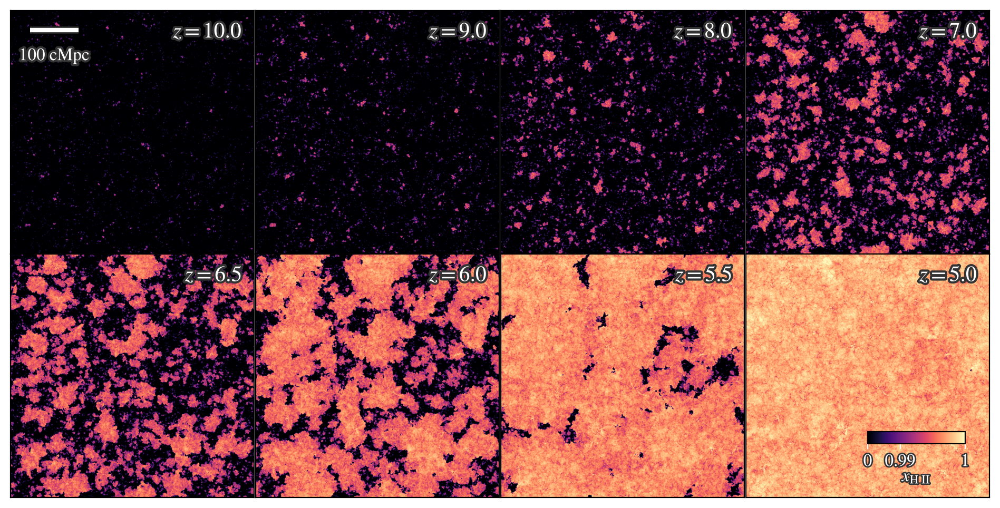

In [12]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LogNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.patheffects as path_effects
# -----------------------------------
# Color scale
#
# We plot the NEUTRAL FRACTION, (1 - x_HII), on a standard logarithmic
# color scale (LogNorm) from 1 (neutral) down to 10^-N_DECADES (highly
# ionized). This is the same transform as before, just expressed as
# what it actually is -- a log scale on the complement -- instead of a
# custom forward/inverse pair. Pixel colors are identical either way;
# this version is just the one you can describe in a methods section
# without hand-waving: "colored by the neutral fraction, 1-x_HII, on a
# base-10 log scale from 1 to 1e-N_DECADES."
#
# CMAP is reversed ("magma_r") because we're now coloring by the
# NEUTRAL fraction: low neutral fraction (= highly ionized) should be
# bright, high neutral fraction (= neutral gas) should be black --
# magma_r puts black at its high end, matching that.
#
# N_DECADES: how many decades of neutral fraction to resolve before
# saturating.
#   4 -> saturates at 1-x_HII = 1e-4  (x_HII = 0.9999)
#   6 -> saturates at 1-x_HII = 1e-6  (x_HII = 0.999999)  [confirmed good]
# -----------------------------------
N_DECADES = 6
CMAP      = "magma_r"
VERBOSE   = True   # print percentiles of (1 - x_HII) so N_DECADES can be tuned
EPS = 10.0 ** (-N_DECADES)
norm = LogNorm(vmin=EPS, vmax=1.0)
# ---- colorbar ticks, expressed in x_HII but placed at the
#      corresponding (1-x_HII) data positions LogNorm actually uses ----
CBAR_TICK_XHII = [0.0, 0.99, 1.0]
CBAR_TICKS  = [max(1.0 - v, EPS) for v in CBAR_TICK_XHII]
CBAR_LABELS = ["0", "0.99", "1"]
# -----------------------------------
# Helper
# -----------------------------------
def get_redshift(ps_file):
    with open(ps_file) as f:
        return float(f.readline().strip())
def hdf5_path(snap):
    if snap <= 428:
        run = "Flagship_new"
    else:
        run = "Flagship_below_z_4p75_new"
    return (
        f"/orcd/data/mvogelsb/005/mkilab001/"
        f"mvogelsblab003/Lab/Thesan-XL/"
        f"{run}/postprocessing/ren_640/"
        f"HII_VolumeFraction/"
        f"HII_VolumeFraction_{snap:03d}.hdf5"
    )
# -----------------------------------
# SNAPSHOTS
# -----------------------------------
snaps = [156, 181, 209, 255, 289, 325, 364, 406]
# -----------------------------------
# FIGURE LAYOUT
# -----------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2, 4,
    wspace=0,
    hspace=0
)
axes = [
    fig.add_subplot(gs[i, j])
    for i in range(2)
    for j in range(4)
]
# -----------------------------------
# LOAD + PLOT HII MAPS
# -----------------------------------
for i, snap in enumerate(snaps):
    PS_file = (
        f"/orcd/data/mvogelsb/004/chcho/compute_J_alpha_H/Tb_H/PS_{snap:03d}.out"
    )
    z = get_redshift(PS_file)
    # ---- mid-plane slice, read directly (no full cube in memory) ----
    with h5py.File(hdf5_path(snap), "r") as f:
        dset = f["/HII_VolumeFraction"]
        N = dset.shape[0]
        f_HII = dset[:, :, N // 2]
    f_HII_plot = np.clip(f_HII, 0.0, 1.0)
    neutral = np.clip(1.0 - f_HII_plot, EPS, 1.0)  # the field actually plotted
    if VERBOSE:
        p = np.percentile(neutral, [1, 25, 50, 75, 99])
        print(
            f"snap {snap:3d}  z={z:5.2f}  "
            f"(1-x_HII) percentiles [1,25,50,75,99]: "
            + "  ".join(f"{v:.2e}" for v in p),
            flush=True
        )
    # ---- plot ----
    ax = axes[i]
    im = ax.imshow(
        neutral.T,
        origin="lower",
        cmap=CMAP,
        norm=norm,
        extent=[0, 500, 0, 500]
    )
    ax.set_xticks([])
    ax.set_yticks([])
    # ---- redshift label ----
    txt = ax.text(
        0.95,
        0.95,
        fr"$z = {z:.1f}$",
        transform=ax.transAxes,
        color="white",
        fontsize=15,
        ha="right",
        va="top"
    )
    txt.set_path_effects([
        path_effects.Stroke(
            linewidth=3,
            foreground="0.2"
        ),
        path_effects.Normal()
    ])
# -----------------------------------
# Inset colorbar inside last panel
# -----------------------------------
ax_last = axes[-1]
cax = inset_axes(
    ax_last,
    width="40%",
    height="5%",
    loc="lower right",
    bbox_to_anchor=(-0.1, 0.22, 1, 1),   # (x, y, w, h) in axes fraction
    bbox_transform=ax_last.transAxes,
    borderpad=0
)
cbar = fig.colorbar(
    im,
    cax=cax,
    orientation="horizontal"
)
cbar.set_ticks(CBAR_TICKS)
cbar.set_ticklabels(CBAR_LABELS)
# the underlying data is (1-x_HII), so low data = high x_HII; flip the
# displayed axis so the bar still reads x_HII = 0 -> 1, left to right
cbar.ax.invert_xaxis()
cbar.ax.tick_params(labelsize=12, colors="white")
cbar.ax.xaxis.set_minor_locator(plt.NullLocator())
for t in cbar.ax.get_xticklabels():
    t.set_path_effects([
        path_effects.Stroke(linewidth=2, foreground="0.2"),
        path_effects.Normal()
    ])
# BOTTOM label = ionization fraction
label = cbar.ax.text(
    0.5,
    -2.1,
    r"$x_{\mathrm{H \ II}}$",
    transform=cbar.ax.transAxes,
    fontsize=12,
    ha="center",
    va="top",
    color="white"
)
label.set_path_effects([
    path_effects.Stroke(linewidth=2, foreground="0.2"),
    path_effects.Normal()
])
# -----------------------------------
# Scale bar: 100 cMpc on the upper-left panel
# -----------------------------------
ax_first = axes[0]
bar_length = 100.0          # cMpc
x0 = 40                     # left end of bar (data units)
y0 = 460                    # height of bar (near top)
ax_first.plot(
    [x0, x0 + bar_length],
    [y0, y0],
    color="white",
    lw=3,
    solid_capstyle="butt",
    path_effects=[
        path_effects.Stroke(linewidth=5, foreground="0.15"),
        path_effects.Normal()
    ]
)
lbl = ax_first.text(
    x0 + bar_length / 2,
    y0 - 35,
    r"$100\ \mathrm{cMpc}$",
    color="white",
    fontsize=12,
    ha="center",
    va="top"
)
lbl.set_path_effects([
    path_effects.Stroke(linewidth=3, foreground="0.2"),
    path_effects.Normal()
])
# -----------------------------------
# SAVE + SHOW
# -----------------------------------
# plt.savefig(
#     "f_HII_map_log_inset.png",
#     dpi=300,
#     bbox_inches="tight"
# )
plt.show()

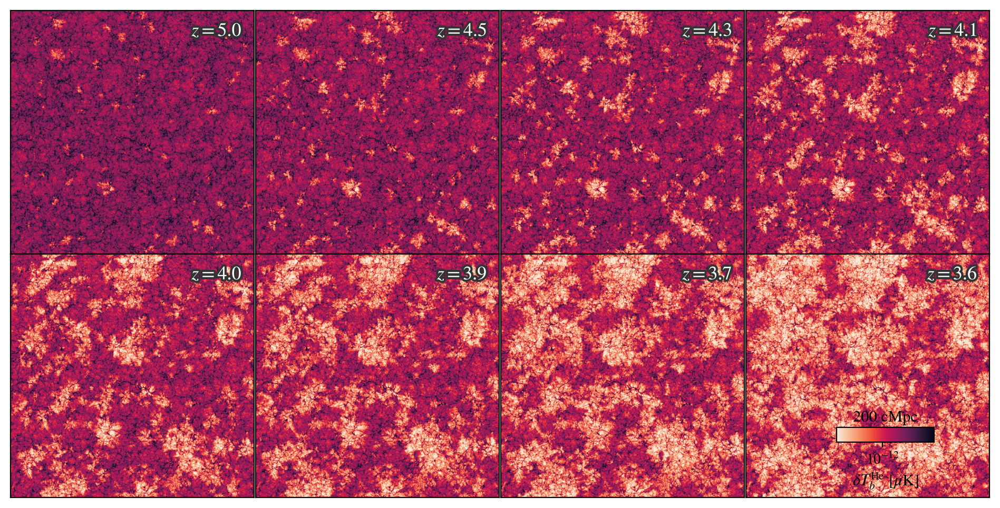

In [18]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import re

from matplotlib.colors import LogNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.patheffects as path_effects


# =====================================
# Helper
# =====================================

def get_redshift(ps_file):
    with open(ps_file) as f:
        return float(f.readline().strip())


# =====================================
# Input files
# =====================================

files = [
    "/orcd/data/mvogelsb/004/chcho/PS_21cm/All_include/He/Tb/RIN_406.hdf5",
    "/orcd/data/mvogelsb/004/chcho/PS_21cm/All_include/He/Tb/RIN_450.hdf5",
    "/orcd/data/mvogelsb/004/chcho/PS_21cm/All_include/He/Tb/RIN_471.hdf5",
    "/orcd/data/mvogelsb/004/chcho/PS_21cm/All_include/He/Tb/RIN_487.hdf5",
    "/orcd/data/mvogelsb/004/chcho/PS_21cm/All_include/He/Tb/RIN_500.hdf5",
    "/orcd/data/mvogelsb/004/chcho/PS_21cm/All_include/He/Tb/RIN_514.hdf5",
    "/orcd/data/mvogelsb/004/chcho/PS_21cm/All_include/He/Tb/RIN_529.hdf5",
    "/orcd/data/mvogelsb/004/chcho/PS_21cm/All_include/He/Tb/RIN_558.hdf5",
]

snaps = [
    int(re.search(r'_(\d+)\.hdf5', f).group(1))
    for f in files
]


# =====================================
# Figure layout
# =====================================

fig = plt.figure(figsize=(12, 6))

gs = gridspec.GridSpec(
    2, 4,
    wspace=0,
    hspace=0
)

axes = [
    fig.add_subplot(gs[i, j])
    for i in range(2)
    for j in range(4)
]


# =====================================
# 1. Load Data & Calculate Percentiles
# =====================================
Tb_slices = []
redshifts = []

for snap in snaps:
    hdf5_file = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/All_include/He/Tb/RIN_{snap:03d}.hdf5"
    PS_file = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/All_include/He/Tb/PS_{snap:03d}.out"
    
    z = get_redshift(PS_file)
    redshifts.append(z)

    with h5py.File(hdf5_file, "r") as f:
        Tb_cube = f["/rin"][:]

    N = Tb_cube.shape[0]
    Tb_slices.append(Tb_cube[:, :, N // 2])

# Combine all slices to find global percentiles
all_Tb = np.array(Tb_slices)

# Filter out zero/negative values to avoid breaking the log scale
positive_Tb = all_Tb[all_Tb > 0] 

if len(positive_Tb) > 0:
    vmin_val = np.percentile(positive_Tb, 1)
    vmax_val = np.percentile(positive_Tb, 99)
else:
    # Fallback just in case the array is completely empty/zero
    vmin_val, vmax_val = 1e-4, 1.0 

# Define the LogNorm with our dynamically calculated percentiles
norm = LogNorm(vmin=vmin_val, vmax=vmax_val)


# =====================================
# 2. Plotting Loop
# =====================================

for i, (Tb, z) in enumerate(zip(Tb_slices, redshifts)):
    ax = axes[i]

    im = ax.imshow(
        Tb.T,
        origin="lower",
        cmap=sns.color_palette("rocket_r", as_cmap=True),
        norm=norm,
        extent=[0, 500, 0, 500]
    )

    # remove ticks
    ax.set_xticks([])
    ax.set_yticks([])

    # =================================
    # Redshift label with boundary
    # =================================

    txt = ax.text(
        0.95,
        0.95,
        fr"$z = {z:.1f}$",
        transform=ax.transAxes,
        color="white",
        fontsize=13,
        ha="right",
        va="top"
    )

    txt.set_path_effects([
        path_effects.Stroke(
            linewidth=3,
            foreground="0.2"
        ),
        path_effects.Normal()
    ])


# =====================================
# Inset colorbar + scale bar
# in last panel
# =====================================

ax_last = axes[-1]

cax = inset_axes(
    ax_last,
    width="40%",
    height="6%",
    loc="lower right",
    borderpad=2.7
)

cbar = fig.colorbar(
    im,
    cax=cax,
    orientation="horizontal"
)

# =====================================
# Format colorbar 
# =====================================

cbar.ax.tick_params(
    labelsize=10,
    colors="black"
)

# -------------------------------------
# TOP label = physical scale bar
# -------------------------------------
title = cbar.ax.set_title(
    "200 cMpc",
    fontsize=11,
    pad=4,
    color="black"
)

# -------------------------------------
# BOTTOM label = Tb quantity
# -------------------------------------
label = cbar.ax.text(
    0.5,
    -2.0,
    r"$\delta T_b^{\mathrm{He}}\ [\mu{\rm K}]$",
    transform=cbar.ax.transAxes,
    fontsize=11,
    ha="center",
    va="top",
    color="black"
)

# =====================================
# Final layout
# =====================================

# plt.savefig(
#     "Tb_He_map_inset.png",
#     dpi=300,
#     bbox_inches="tight"
# )

plt.show()

### Hydrogen 21 cm brightness temperature map

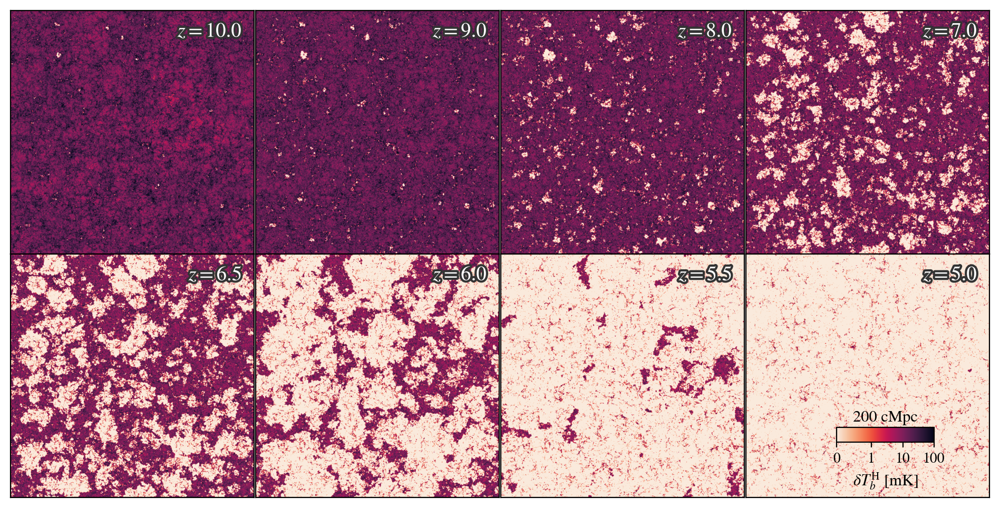

In [75]:
import re
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

from matplotlib.colors import SymLogNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.patheffects as path_effects


# =====================================
# Helper
# =====================================

def get_redshift(ps_file):
    with open(ps_file) as f:
        return float(f.readline().strip())


# =====================================
# Input files
# =====================================

files = [
    "./TS_TK/H/Tb/PS_Tb_H_156.out",
    "./TS_TK/H/Tb/PS_Tb_H_181.out",
    "./TS_TK/H/Tb/PS_Tb_H_209.out",
    "./TS_TK/H/Tb/PS_Tb_H_255.out",
    "./TS_TK/H/Tb/PS_Tb_H_289.out",
    "./TS_TK/H/Tb/PS_Tb_H_325.out",
    "./TS_TK/H/Tb/PS_Tb_H_364.out",
    "./TS_TK/H/Tb/PS_Tb_H_406.out",
]

# Extract snapshot numbers
snaps = [int(re.search(r'_(\d+)\.out', f).group(1)) for f in files]
snaps = snaps[:8]


# =====================================
# Figure layout
# =====================================

fig = plt.figure(figsize=(12, 6))

gs = gridspec.GridSpec(
    2, 4,
    wspace=0,
    hspace=0
)

axes = [
    fig.add_subplot(gs[i, j])
    for i in range(2)
    for j in range(4)
]


# =====================================
# Color normalization
# Tb map with symlog including zero
# =====================================

norm = SymLogNorm(
    linthresh=1,
    linscale=1,
    vmin=0,
    vmax=100,
    base=10
)


# =====================================
# Load + plot hydrogen Tb maps
# =====================================

for i, snap in enumerate(snaps):

    hdf5_file = (
        f"/orcd/data/mvogelsb/004/chcho/PS_21cm/"
        f"TS_TK/H/Tb/Tb_H_{snap:03d}.hdf5"
    )

    PS_file = (
        f"./TS_TK/H/Tb/PS_Tb_H_{snap:03d}.out"
    )

    z = get_redshift(PS_file)

    # ---------------------------------
    # Load cube
    # ---------------------------------

    with h5py.File(hdf5_file, "r") as f:
        Tb_cube = f["/rin"][:]

    N = Tb_cube.shape[0]

    # Mid-plane slice
    Tb = Tb_cube[:, :, N // 2]

    ax = axes[i]

    im = ax.imshow(
        Tb.T,
        origin="lower",
        cmap=sns.color_palette(
            "rocket_r",
            as_cmap=True
        ),
        norm=norm,
        extent=[0, 500, 0, 500]
    )

    # Remove ticks
    ax.set_xticks([])
    ax.set_yticks([])

    # =================================
    # Better redshift label
    # (from new figure style)
    # =================================

    txt = ax.text(
        0.95,
        0.95,
        fr"$z = {z:.1f}$",
        transform=ax.transAxes,
        color="white",
        fontsize=14,
        ha="right",
        va="top"
    )

    txt.set_path_effects([
        path_effects.Stroke(
            linewidth=3,
            foreground="0.2"
        ),
        path_effects.Normal()
    ])


# =====================================
# Inset colorbar + scale bar
# in last panel
# =====================================

ax_last = axes[-1]

cax = inset_axes(
    ax_last,
    width="40%",
    height="6%",
    loc="lower right",
    borderpad=2.7
)

# THIS creates the actual bar
cbar = fig.colorbar(
    im,
    cax=cax,
    orientation="horizontal"
)

# Tick locations
cbar.set_ticks([
    0,
    1,
    10,
    100
])

cbar.set_ticklabels([
    "0",
    "1",
    "10",
    "100"
])


# =====================================
# Make colorbar texts visible using
# outline (same style as redshift text)
# =====================================

import matplotlib.patheffects as path_effects

# -------------------------------------
# Tick labels with outline
# -------------------------------------

cbar.ax.tick_params(
    labelsize=10,
    colors="black"   # white text
)

#for tick in cbar.ax.get_xticklabels():
#    tick.set_color("white")
#    tick.set_path_effects([
#        path_effects.Stroke(
#            linewidth=2,
#            foreground="black"
#        ),
#        path_effects.Normal()
#    ])

# -------------------------------------
# TOP label = physical scale bar
# -------------------------------------

title = cbar.ax.set_title(
    "200 cMpc",
    fontsize=11,
    pad=4,
    color="black"
)

#title.set_path_effects([
#    path_effects.Stroke(
#        linewidth=2,
#        foreground="black"
#    ),
#    path_effects.Normal()
#])

# -------------------------------------
# BOTTOM label = Tb quantity
# -------------------------------------

label = cbar.ax.text(
    0.5,
    -2.0,
    r"$\delta T_b^{\mathrm{H}}\ [{\rm mK}]$",
    transform=cbar.ax.transAxes,
    fontsize=11,
    ha="center",
    va="top",
    color="black"
)

#label.set_path_effects([
#    path_effects.Stroke(
#        linewidth=2,
#        foreground="black"
#    ),
#    path_effects.Normal()
#])

# =====================================
# Final layout
# =====================================

#plt.tight_layout()

# plt.savefig(
#     "Tb_H_map_symlog_inset.png",
#     dpi=300,
#     bbox_inches="tight"
# )

plt.show()

## Hydrogen ionization fraction

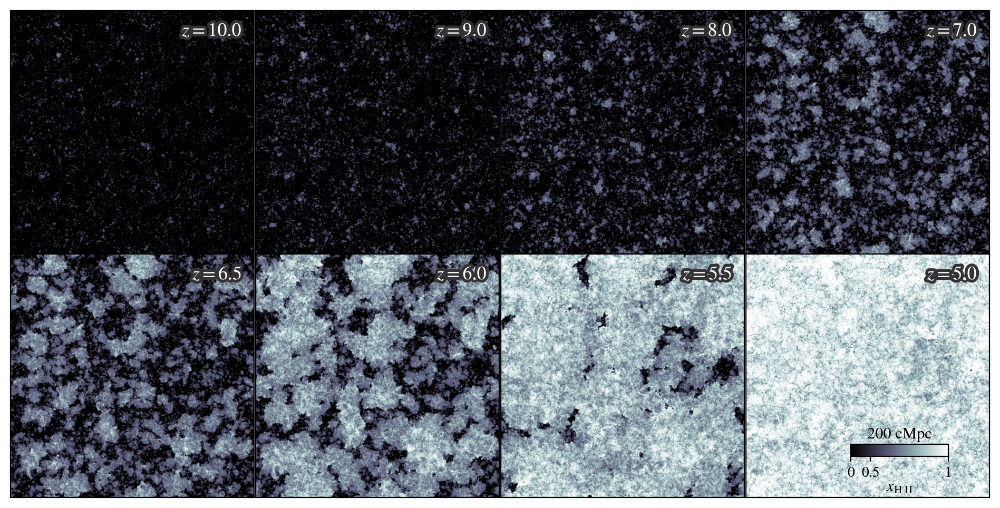

In [2]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.patheffects as path_effects


# -----------------------------------
# Helper
# -----------------------------------

def get_redshift(ps_file):
    with open(ps_file) as f:
        return float(f.readline().strip())


# -----------------------------------
# SNAPSHOTS
# -----------------------------------

snaps = [156, 181, 209, 255, 289, 325, 364, 406]


# -----------------------------------
# FIGURE LAYOUT
# -----------------------------------

fig = plt.figure(figsize=(12, 6))

gs = gridspec.GridSpec(
    2, 4,
    wspace=0,
    hspace=0
)

axes = [
    fig.add_subplot(gs[i, j])
    for i in range(2)
    for j in range(4)
]


# -----------------------------------
# LOG SCALE SETTINGS
# -----------------------------------

# avoid log10(0)
floor = 1e-2

# colorbar range: log10(x_HII)
#norm = Normalize(
#    vmin=-2,
#    vmax=1
#)

from matplotlib.colors import PowerNorm

#norm = PowerNorm(gamma=0.3, vmin=0, vmax=1)

from matplotlib.colors import FuncNorm

all_vals = []
for snap in snaps:
    if snap <= 428:
        hdf5_file = (
            f"/orcd/data/mvogelsb/005/mkilab001/"
            f"mvogelsblab003/Lab/Thesan-XL/"
            f"Flagship_new/postprocessing/ren_640/"
            f"HII_VolumeFraction/"
            f"HII_VolumeFraction_{snap:03d}.hdf5"
        )
    else:
        hdf5_file = (
            f"/orcd/data/mvogelsb/005/mkilab001/"
            f"mvogelsblab003/Lab/Thesan-XL/"
            f"Flagship_below_z_4p75_new/postprocessing/ren_640/"
            f"HII_VolumeFraction/"
            f"HII_VolumeFraction_{snap:03d}.hdf5"
        )

    with h5py.File(hdf5_file, "r") as f:
        data = f["/HII_VolumeFraction"][:]
    all_vals.append(data[data > 1e-3].ravel())

all_vals = np.sort(np.concatenate(all_vals))
cdf = np.linspace(0, 1, len(all_vals))

def forward(x): return np.interp(x, all_vals, cdf)
def inverse(y): return np.interp(y, cdf, all_vals)

norm = FuncNorm((forward, inverse), vmin=1e-3, vmax=1)
# And plot the raw fraction, not log

# -----------------------------------
# LOAD + PLOT HII MAPS
# -----------------------------------

for i, snap in enumerate(snaps):

    # -----------------------------------
    # File paths
    # -----------------------------------

    if snap <= 428:
        hdf5_file = (
            f"/orcd/data/mvogelsb/005/mkilab001/"
            f"mvogelsblab003/Lab/Thesan-XL/"
            f"Flagship_new/postprocessing/ren_640/"
            f"HII_VolumeFraction/"
            f"HII_VolumeFraction_{snap:03d}.hdf5"
        )
    else:
        hdf5_file = (
            f"/orcd/data/mvogelsb/005/mkilab001/"
            f"mvogelsblab003/Lab/Thesan-XL/"
            f"Flagship_below_z_4p75_new/postprocessing/ren_640/"
            f"HII_VolumeFraction/"
            f"HII_VolumeFraction_{snap:03d}.hdf5"
        )

    PS_file = (
        f"/orcd/data/mvogelsb/004/chcho/compute_J_alpha_H/Tb_H/PS_{snap:03d}.out"
    )

    z = get_redshift(PS_file)

    # -----------------------------------
    # Load cube
    # -----------------------------------

    with h5py.File(hdf5_file, "r") as f:
        f_HII_cube = f["/HII_VolumeFraction"][:]

    # -----------------------------------
    # Mid-plane slice
    # -----------------------------------

    N = f_HII_cube.shape[0]
    f_HII = f_HII_cube[:, :, N // 2]

    # -----------------------------------
    # Convert to log10 scale
    # -----------------------------------

    #f_HII_plot = np.log10(
    #    np.clip(f_HII, floor, 1.0)
    #)
    f_HII_plot = np.clip(f_HII, 0, 1)

    # -----------------------------------
    # Plot
    # -----------------------------------

    ax = axes[i]

    im = ax.imshow(
        f_HII_plot.T,
        origin="lower",
        cmap="bone",
        norm=norm,
        extent=[0, 500, 0, 500]
    )

    # remove ticks
    ax.set_xticks([])
    ax.set_yticks([])

    # -----------------------------------
    # Redshift label with boundary
    # -----------------------------------

    txt = ax.text(
        0.95,
        0.95,
        fr"$z = {z:.1f}$",
        transform=ax.transAxes,
        color="white",
        fontsize=13,
        ha="right",
        va="top"
    )

    txt.set_path_effects([
        path_effects.Stroke(
            linewidth=4,
            foreground="0.2"
        ),
        path_effects.Normal()
    ])


# -----------------------------------
# Inset colorbar inside last panel
# -----------------------------------

ax_last = axes[-1]

cax = inset_axes(
    ax_last,
    width="40%",
    height="5%",
    loc="lower right",
    borderpad=2.0
)

cbar = fig.colorbar(
    im,
    cax=cax,
    orientation="horizontal"
)

cbar.set_ticks([1e-3, 0.5, 1.0])
cbar.set_ticklabels(["0", "0.5", "1"])
cbar.ax.tick_params(labelsize=10, colors="black")


# TOP label = physical scale
cbar.ax.set_title(
    "200 cMpc",
    fontsize=11,
    pad=4
)

# BOTTOM label = ionization fraction
cbar.ax.text(
    0.5,
    -2.0,
    r"$x_{\mathrm{H \ II}}$", #\log 
    transform=cbar.ax.transAxes,
    fontsize=11,
    ha="center",
    va="top",
    color="black"
)
# -----------------------------------
# SAVE + SHOW
# -----------------------------------

# plt.savefig(
#     "f_HII_map_log_inset.png",
#     dpi=300,
#     bbox_inches="tight"
# )

plt.show()

## Helium 3.46 cm brightness temperature

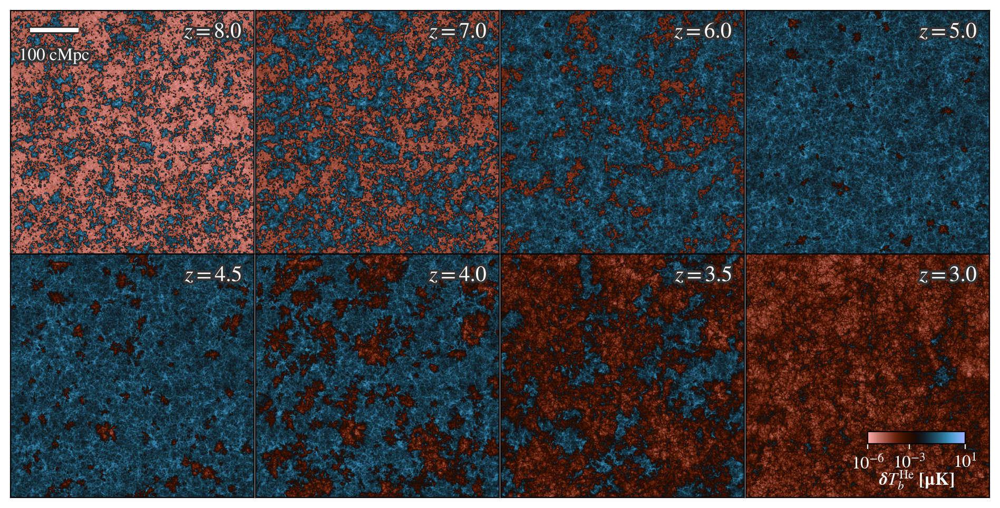

In [32]:
import re
import h5py
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patheffects as path_effects
from matplotlib.colors import LogNorm
from matplotlib.ticker import NullLocator
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


# =====================================
# Helper
# =====================================

def get_redshift(ps_file):
    with open(ps_file) as f:
        return float(f.readline().strip())


# =====================================
# Input files
# =====================================

files = [
    "/orcd/data/mvogelsb/004/chcho/compute_J_alpha_He/Tb_He/RIN_209.hdf5",
    "/orcd/data/mvogelsb/004/chcho/compute_J_alpha_He/Tb_He/RIN_255.hdf5",
    "/orcd/data/mvogelsb/004/chcho/compute_J_alpha_He/Tb_He/RIN_325.hdf5",
    "/orcd/data/mvogelsb/004/chcho/compute_J_alpha_He/Tb_He/RIN_406.hdf5",
    "/orcd/data/mvogelsb/004/chcho/compute_J_alpha_He/Tb_He/RIN_452.hdf5",
    "/orcd/data/mvogelsb/004/chcho/compute_J_alpha_He/Tb_He/RIN_501.hdf5",
    "/orcd/data/mvogelsb/004/chcho/compute_J_alpha_He/Tb_He/RIN_582.hdf5",
    "/orcd/data/mvogelsb/004/chcho/compute_J_alpha_He/Tb_He/RIN_705.hdf5",
]

snaps = [
    int(re.search(r'_(\d+)\.hdf5', f).group(1))
    for f in files
]


# =====================================
# Figure layout (better publication size)
# =====================================

fig = plt.figure(figsize=(12, 6))

gs = gridspec.GridSpec(
    2, 4,
    wspace=0,
    hspace=0
)

axes = [
    fig.add_subplot(gs[i, j])
    for i in range(2)
    for j in range(4)
]


# =====================================
# Color normalization
# =====================================

norm = LogNorm(vmin=1e-6, vmax=10)


# =====================================
# Load + plot helium Tb maps
# =====================================

for i, snap in enumerate(snaps):

    hdf5_file = (
        f"/orcd/data/mvogelsb/004/chcho/compute_J_alpha_He/Tb_He/"
        f"RIN_{snap:03d}.hdf5"
    )

    PS_file = (
        f"/orcd/data/mvogelsb/004/chcho/PS_21cm/All_include/He/Tb/"
        f"PS_{snap:03d}.out"
    )

    z = get_redshift(PS_file)

    # ---------------------------------
    # Load cube
    # ---------------------------------

    with h5py.File(hdf5_file, "r") as f:
        Tb_cube = f["/rin"][:]

    N = Tb_cube.shape[0]
    Tb = Tb_cube[:, :, N // 2]

    ax = axes[i]

    im = ax.imshow(
        Tb.T,
        origin="lower",
        cmap=sns.color_palette(
            "berlin_r",
            as_cmap=True
        ),
        norm=norm,
        extent=[0, 500, 0, 500]
    )

    # remove ticks
    ax.set_xticks([])
    ax.set_yticks([])

    # =================================
    # Redshift label with boundary
    # =================================

    txt = ax.text(
        0.95,
        0.95,
        fr"$z = {z:.1f}$",
        transform=ax.transAxes,
        color="white",
        fontsize=15,
        ha="right",
        va="top"
    )

    txt.set_path_effects([
        path_effects.Stroke(
            linewidth=3,
            foreground="0.2"
        ),
        path_effects.Normal()
    ])


# =====================================
# Inset colorbar + scale bar
# in last panel
# =====================================

ax_last = axes[-1]

cax = inset_axes(
    ax_last,
    width="40%",
    height="5%",
    loc="lower right",
    bbox_to_anchor=(-0.1, 0.22, 1, 1),   # (x, y, w, h) in axes fraction
    bbox_transform=ax_last.transAxes,
    borderpad=0
)

cbar = fig.colorbar(
    im,
    cax=cax,
    orientation="horizontal"
)

cbar.set_ticks([1e-6, 1e-3, 1e1])
cbar.set_ticklabels([r"$10^{-6}$", r"$10^{-3}$", r"$10^{1}$"])
cbar.ax.xaxis.set_minor_locator(NullLocator())   # remove minor ticks


# -------------------------------------
# Tick labels
# -------------------------------------

cbar.ax.tick_params(
    labelsize=12,
    colors="white"
)


# -------------------------------------
# BOTTOM label = Tb quantity
# -------------------------------------

label = cbar.ax.text(
    0.5,
    -2.1,
    r"$\boldsymbol{\delta T_b^{\mathrm{He}}}\ \mathbf{[\mu K]}$",
    transform=cbar.ax.transAxes,
    fontsize=12,
    ha="center",
    va="top",
    color="white"
)


# =====================================
# Scale bar: 100 cMpc on the upper-left panel
# =====================================

ax_first = axes[0]

# Bar geometry in data coordinates (extent is 0-500 cMpc)
bar_length = 100.0          # cMpc
x0 = 40                     # left end of bar (data units)
y0 = 460                    # height of bar (near top)

# The bar itself
ax_first.plot(
    [x0, x0 + bar_length],
    [y0, y0],
    color="white",
    lw=3,
    solid_capstyle="butt",
    path_effects=[
        path_effects.Stroke(linewidth=5, foreground="0.15"),
        path_effects.Normal()
    ]
)

# Label above the bar
lbl = ax_first.text(
    x0 + bar_length / 2,
    y0 - 35,
    r"$100\ \mathrm{cMpc}$",
    color="white",
    fontsize=12,
    ha="center",
    va="top"
)
lbl.set_path_effects([
    path_effects.Stroke(linewidth=3, foreground="0.2"),
    path_effects.Normal()
])


# =====================================
# Final layout
# =====================================

# plt.savefig(
#     "Tb_He_map_inset.png",
#     dpi=300,
#     bbox_inches="tight"
# )

plt.show()

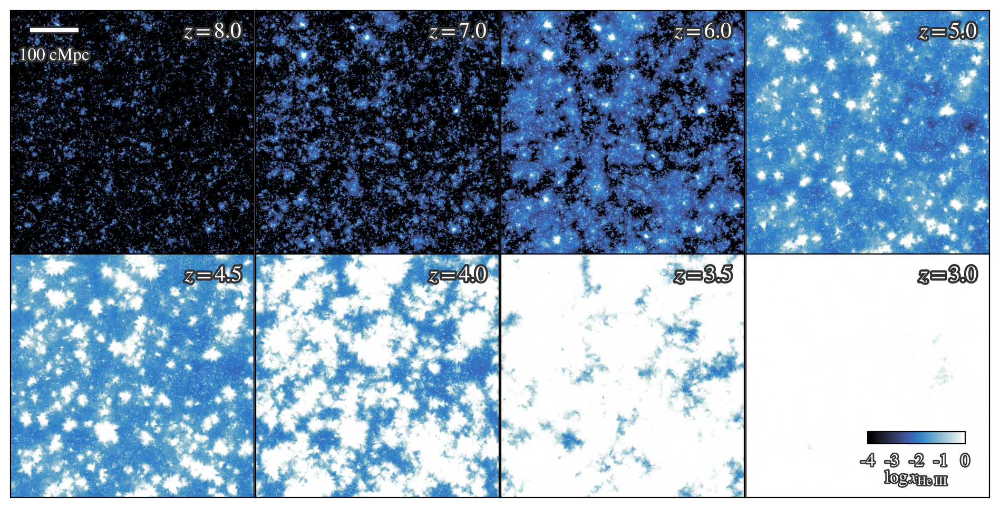

In [34]:
# CONSIDER Y_FRAC!!!
HYDROGEN_MASSFRAC = 0.76
y_frac = (1.0 - HYDROGEN_MASSFRAC) / (4.0 * HYDROGEN_MASSFRAC)

import re
import h5py
import numpy as np
import seaborn as sns
import cmasher as cmr
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patheffects as path_effects

from matplotlib.colors import Normalize
from matplotlib.ticker import NullLocator
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


# =====================================
# Helper
# =====================================

def get_redshift(ps_file):
    with open(ps_file) as f:
        return float(f.readline().strip())


# =====================================
# Input files
# =====================================

files = [
    "./TS_TK/Tb_He/old/PS_Tb_He_209.out",
    "./TS_TK/Tb_He/old/PS_Tb_He_255.out",
    "./TS_TK/Tb_He/old/PS_Tb_He_325.out",
    "./TS_TK/Tb_He/old/PS_Tb_He_406.out",
    "./TS_TK/Tb_He/old/PS_Tb_He_452.out",
    "./TS_TK/Tb_He/old/PS_Tb_He_501.out",
    "./TS_TK/Tb_He/old/PS_Tb_He_582.out",
    "./TS_TK/Tb_He/old/PS_Tb_He_705.out",
]

snaps = [
    int(re.search(r'_(\d+)\.out', f).group(1))
    for f in files
]


# =====================================
# Figure layout (publication size)
# =====================================

fig = plt.figure(figsize=(12, 6))

gs = gridspec.GridSpec(
    2, 4,
    wspace=0,
    hspace=0
)

axes = [
    fig.add_subplot(gs[i, j])
    for i in range(2)
    for j in range(4)
]


# =====================================
# Log scale settings
# =====================================

floor = 1e-4

norm = Normalize(
    vmin=-4,
    vmax=0
)


# =====================================
# Load + plot HeIII maps
# =====================================

for i, snap in enumerate(snaps):

    # ---------------------------------
    # Path switch
    # ---------------------------------

    if snap <= 428:
        hdf5_file = (
            f"/orcd/data/mvogelsb/005/mkilab001/"
            f"mvogelsblab003/Lab/Thesan-XL/"
            f"Flagship_new/postprocessing/ren_640/"
            f"HeIII_VolumeFraction/"
            f"HeIII_VolumeFraction_{snap:03d}.hdf5"
        )
    else:
        hdf5_file = (
            f"/orcd/data/mvogelsb/005/mkilab001/"
            f"mvogelsblab003/Lab/Thesan-XL/"
            f"Flagship_below_z_4p75_new/postprocessing/ren_640/"
            f"HeIII_VolumeFraction/"
            f"HeIII_VolumeFraction_{snap:03d}.hdf5"
        )

    PS_file = (
        f"/orcd/data/mvogelsb/004/chcho/PS_21cm/"
        f"TS_TK/Tb_He/old/PS_Tb_He_{snap:03d}.out"
    )

    z = get_redshift(PS_file)

    # ---------------------------------
    # Load cube
    # ---------------------------------

    with h5py.File(hdf5_file, "r") as f:
        f_HeIII_cube = (
            f["/HeIII_VolumeFraction"][:] / y_frac
        )

    N = f_HeIII_cube.shape[0]
    f_HeIII = f_HeIII_cube[:, :, N // 2]

    # ---------------------------------
    # Log transform
    # ---------------------------------

    f_HeIII_plot = np.log10(
        np.clip(f_HeIII, floor, 1.0)
    )

    ax = axes[i]

    im = ax.imshow(
        f_HeIII_plot.T,
        origin="lower",
        cmap="cmr.arctic",
        norm=norm,
        extent=[0, 500, 0, 500]
    )

    ax.set_xticks([])
    ax.set_yticks([])

    # =================================
    # Redshift label with boundary
    # =================================

    txt = ax.text(
        0.95,
        0.95,
        fr"$z = {z:.1f}$",
        transform=ax.transAxes,
        color="white",
        fontsize=15,
        ha="right",
        va="top"
    )

    txt.set_path_effects([
        path_effects.Stroke(
            linewidth=3,
            foreground="0.2"
        ),
        path_effects.Normal()
    ])


# =====================================
# Inset colorbar in last panel
# =====================================

ax_last = axes[-1]

cax = inset_axes(
    ax_last,
    width="40%",
    height="5%",
    loc="lower right",
    bbox_to_anchor=(-0.1, 0.22, 1, 1),   # (x, y, w, h) in axes fraction
    bbox_transform=ax_last.transAxes,
    borderpad=0
)

cbar = fig.colorbar(
    im,
    cax=cax,
    orientation="horizontal"
)

cbar.set_ticks([-4, -3, -2, -1, 0])
cbar.set_ticklabels(["-4", "-3", "-2", "-1", "0"])
cbar.ax.xaxis.set_minor_locator(NullLocator())

cbar.ax.tick_params(
    labelsize=12,
    colors="white"
)

for t in cbar.ax.get_xticklabels():
    t.set_path_effects([
        path_effects.Stroke(linewidth=2, foreground="0.2"),
        path_effects.Normal()
    ])


# -------------------------------------
# BOTTOM label = ionization fraction
# -------------------------------------

label = cbar.ax.text(
    0.5,
    -2.1,
    r"$\log x_{\mathrm{He \ III}}$",
    transform=cbar.ax.transAxes,
    fontsize=12,
    ha="center",
    va="top",
    color="white"
)
label.set_path_effects([
    path_effects.Stroke(linewidth=2, foreground="0.2"),
    path_effects.Normal()
])


# =====================================
# Scale bar: 100 cMpc on the upper-left panel
# =====================================

ax_first = axes[0]

# Bar geometry in data coordinates (extent is 0-500 cMpc)
bar_length = 100.0          # cMpc
x0 = 40                     # left end of bar (data units)
y0 = 460                    # height of bar (near top)

# The bar itself
ax_first.plot(
    [x0, x0 + bar_length],
    [y0, y0],
    color="white",
    lw=3,
    solid_capstyle="butt",
    path_effects=[
        path_effects.Stroke(linewidth=5, foreground="0.15"),
        path_effects.Normal()
    ]
)

# Label above the bar
lbl = ax_first.text(
    x0 + bar_length / 2,
    y0 - 35,
    r"$100\ \mathrm{cMpc}$",
    color="white",
    fontsize=12,
    ha="center",
    va="top"
)
lbl.set_path_effects([
    path_effects.Stroke(linewidth=3, foreground="0.2"),
    path_effects.Normal()
])


# =====================================
# Save + show
# =====================================

# plt.savefig(
#     "f_HeIII_inset.png",
#     dpi=300,
#     bbox_inches="tight"
# )

plt.show()

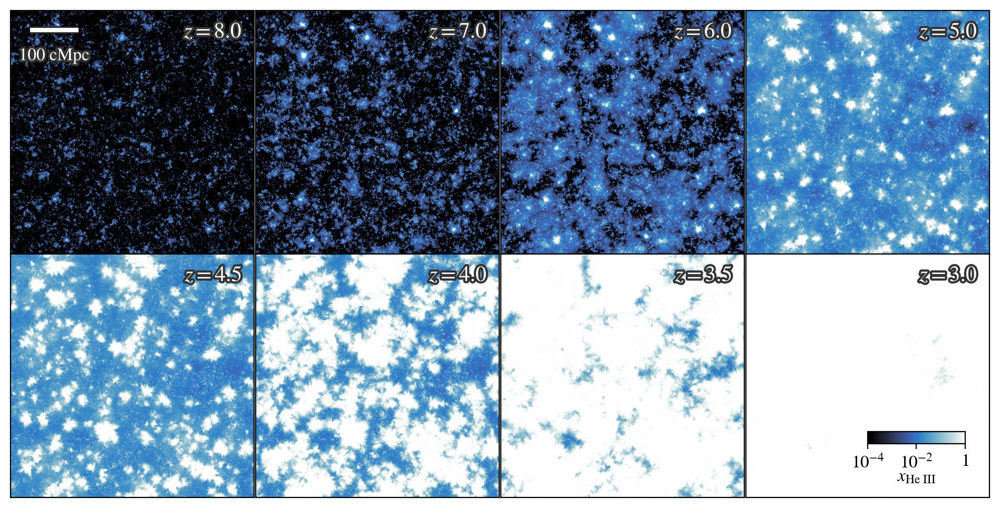

In [39]:
# CONSIDER Y_FRAC!!!
HYDROGEN_MASSFRAC = 0.76
y_frac = (1.0 - HYDROGEN_MASSFRAC) / (4.0 * HYDROGEN_MASSFRAC)

import re
import h5py
import numpy as np
import seaborn as sns
import cmasher as cmr
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patheffects as path_effects

from matplotlib.colors import Normalize
from matplotlib.ticker import NullLocator
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


# =====================================
# Helper
# =====================================

def get_redshift(ps_file):
    with open(ps_file) as f:
        return float(f.readline().strip())


# =====================================
# Input files
# =====================================

files = [
    "./TS_TK/Tb_He/old/PS_Tb_He_209.out",
    "./TS_TK/Tb_He/old/PS_Tb_He_255.out",
    "./TS_TK/Tb_He/old/PS_Tb_He_325.out",
    "./TS_TK/Tb_He/old/PS_Tb_He_406.out",
    "./TS_TK/Tb_He/old/PS_Tb_He_452.out",
    "./TS_TK/Tb_He/old/PS_Tb_He_501.out",
    "./TS_TK/Tb_He/old/PS_Tb_He_582.out",
    "./TS_TK/Tb_He/old/PS_Tb_He_705.out",
]

snaps = [
    int(re.search(r'_(\d+)\.out', f).group(1))
    for f in files
]


# =====================================
# Figure layout (publication size)
# =====================================

fig = plt.figure(figsize=(12, 6))

gs = gridspec.GridSpec(
    2, 4,
    wspace=0,
    hspace=0
)

axes = [
    fig.add_subplot(gs[i, j])
    for i in range(2)
    for j in range(4)
]


# =====================================
# Log scale settings
# Data are log10(x_HeIII); the colorbar is labelled in fraction units.
# =====================================

floor = 1e-4

norm = Normalize(
    vmin=-4,
    vmax=0
)

CBAR_TICKS  = [-4, -2, 0]
CBAR_LABELS = [
    r"$10^{-4}$",
    #r"$10^{-3}$",
    r"$10^{-2}$",
    #r"$10^{-1}$",
    r"$1$",
]


# =====================================
# Load + plot HeIII maps
# =====================================

for i, snap in enumerate(snaps):

    # ---------------------------------
    # Path switch
    # ---------------------------------

    if snap <= 428:
        hdf5_file = (
            f"/orcd/data/mvogelsb/005/mkilab001/"
            f"mvogelsblab003/Lab/Thesan-XL/"
            f"Flagship_new/postprocessing/ren_640/"
            f"HeIII_VolumeFraction/"
            f"HeIII_VolumeFraction_{snap:03d}.hdf5"
        )
    else:
        hdf5_file = (
            f"/orcd/data/mvogelsb/005/mkilab001/"
            f"mvogelsblab003/Lab/Thesan-XL/"
            f"Flagship_below_z_4p75_new/postprocessing/ren_640/"
            f"HeIII_VolumeFraction/"
            f"HeIII_VolumeFraction_{snap:03d}.hdf5"
        )

    PS_file = (
        f"/orcd/data/mvogelsb/004/chcho/PS_21cm/"
        f"TS_TK/Tb_He/old/PS_Tb_He_{snap:03d}.out"
    )

    z = get_redshift(PS_file)

    # ---------------------------------
    # Load cube
    # ---------------------------------

    with h5py.File(hdf5_file, "r") as f:
        f_HeIII_cube = (
            f["/HeIII_VolumeFraction"][:] / y_frac
        )

    N = f_HeIII_cube.shape[0]
    f_HeIII = f_HeIII_cube[:, :, N // 2]

    # ---------------------------------
    # Log transform
    # ---------------------------------

    f_HeIII_plot = np.log10(
        np.clip(f_HeIII, floor, 1.0)
    )

    ax = axes[i]

    im = ax.imshow(
        f_HeIII_plot.T,
        origin="lower",
        cmap="cmr.arctic",
        norm=norm,
        extent=[0, 500, 0, 500]
    )

    ax.set_xticks([])
    ax.set_yticks([])

    # =================================
    # Redshift label with boundary
    # =================================

    txt = ax.text(
        0.95,
        0.95,
        fr"$z = {z:.1f}$",
        transform=ax.transAxes,
        color="white",
        fontsize=15,
        ha="right",
        va="top"
    )

    txt.set_path_effects([
        path_effects.Stroke(
            linewidth=3,
            foreground="0.2"
        ),
        path_effects.Normal()
    ])


# =====================================
# Inset colorbar in last panel
# =====================================

ax_last = axes[-1]

cax = inset_axes(
    ax_last,
    width="40%",
    height="5%",
    loc="lower right",
    bbox_to_anchor=(-0.1, 0.22, 1, 1),   # (x, y, w, h) in axes fraction
    bbox_transform=ax_last.transAxes,
    borderpad=0
)

cbar = fig.colorbar(
    im,
    cax=cax,
    orientation="horizontal"
)

cbar.set_ticks(CBAR_TICKS)
cbar.set_ticklabels(CBAR_LABELS)
cbar.ax.xaxis.set_minor_locator(NullLocator())

cbar.ax.tick_params(
    labelsize=12,
    colors="black"
)

#for t in cbar.ax.get_xticklabels():
#    t.set_path_effects([
#        path_effects.Stroke(linewidth=2, foreground="0.2"),
#        path_effects.Normal()
#    ])


# -------------------------------------
# BOTTOM label = ionization fraction
# -------------------------------------

label = cbar.ax.text(
    0.5,
    -2.1,
    r"$x_{\mathrm{He \ III}}$",
    transform=cbar.ax.transAxes,
    fontsize=12,
    ha="center",
    va="top",
    color="black"
)
#label.set_path_effects([
#    path_effects.Stroke(linewidth=2, foreground="0.2"),
#    path_effects.Normal()
#])


# =====================================
# Scale bar: 100 cMpc on the upper-left panel
# =====================================

ax_first = axes[0]

# Bar geometry in data coordinates (extent is 0-500 cMpc)
bar_length = 100.0          # cMpc
x0 = 40                     # left end of bar (data units)
y0 = 460                    # height of bar (near top)

# The bar itself
ax_first.plot(
    [x0, x0 + bar_length],
    [y0, y0],
    color="white",
    lw=3,
    solid_capstyle="butt",
    path_effects=[
        path_effects.Stroke(linewidth=5, foreground="0.15"),
        path_effects.Normal()
    ]
)

# Label above the bar
lbl = ax_first.text(
    x0 + bar_length / 2,
    y0 - 35,
    r"$100\ \mathrm{cMpc}$",
    color="white",
    fontsize=12,
    ha="center",
    va="top"
)
lbl.set_path_effects([
    path_effects.Stroke(linewidth=3, foreground="0.2"),
    path_effects.Normal()
])


# =====================================
# Save + show
# =====================================

# plt.savefig(
#     "f_HeIII_inset.png",
#     dpi=300,
#     bbox_inches="tight"
# )

plt.show()

## Dummy

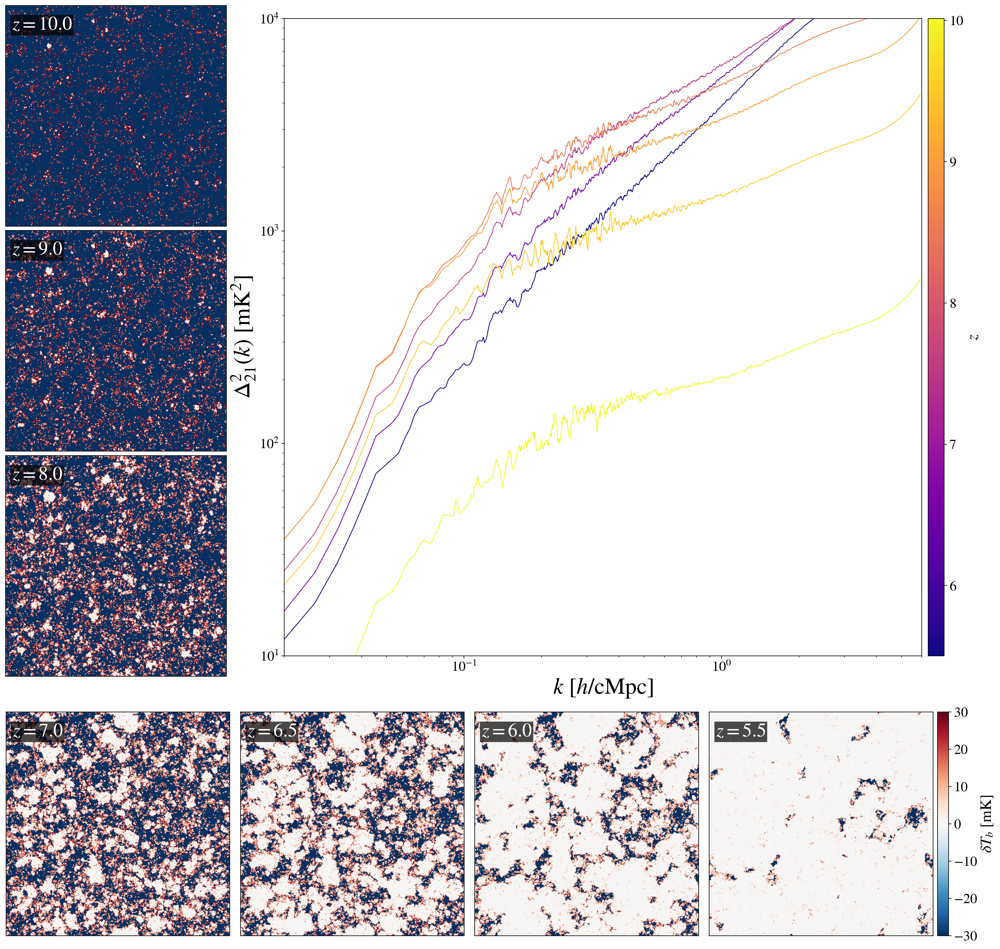

In [72]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import TwoSlopeNorm, Normalize
from matplotlib.cm import ScalarMappable
import matplotlib as mpl
from scipy.signal import savgol_filter
import h5py
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# -----------------------------------
# snapshots
# -----------------------------------

snaps = [156, 181, 209, 255, 289, 325, 364]
z_labels = [10.0, 9.0, 8.0, 7.0, 6.5, 6.0, 5.5]

# -----------------------------------
# normalization
# -----------------------------------

norm = TwoSlopeNorm(vmin=-30, vcenter=0, vmax=30)

# -----------------------------------
# FIGURE LAYOUT (CRITICAL FIX)
# -----------------------------------

fig = plt.figure(figsize=(18.5,18.5))

gs = gridspec.GridSpec(
    2, 2,
    height_ratios=[3, 1],   # ← THIS is the correct relationship
    width_ratios=[1, 3],
    hspace=0.08,
    wspace=0.08
)

# -----------------------------------
# LEFT COLUMN (top-left)
# -----------------------------------

gs_left = gs[0,0].subgridspec(3,1, hspace=0.02)
axes_left = [fig.add_subplot(gs_left[i,0]) for i in range(3)]

# -----------------------------------
# PS PANEL
# -----------------------------------

ax_ps = fig.add_subplot(gs[0,1])

# -----------------------------------
# BOTTOM ROW (4 maps)
# -----------------------------------

gs_bottom = gs[1,:].subgridspec(1,4, wspace=0.03)
axes_bottom = [fig.add_subplot(gs_bottom[0,i]) for i in range(4)]

# -----------------------------------
# LOAD SLICE (HDF5)
# -----------------------------------

def load_slice(snap):
    file = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/TK_ad/H/Tb/RIN_H_ad_{snap:03d}.out"
    
    with h5py.File(file, "r") as f:
        Tb_cube = f["rin"][:]

    if Tb_cube.ndim == 1:
        N = int(round(len(Tb_cube)**(1/3)))
        Tb_cube = Tb_cube.reshape((N, N, N))
    else:
        N = Tb_cube.shape[0]

    return Tb_cube[:, :, N//2]

# -----------------------------------
# LOAD PS
# -----------------------------------

def load_ps(filename, skiprows=5):
    with open(filename) as f:
        lines = f.readlines()
        z = float(lines[0])
        mean = float(lines[2]) / float(lines[3])

    data = np.loadtxt(filename, skiprows=skiprows)

    k = data[:,0]
    delta2 = data[:,1]
    nmodes = data[:,3]

    delta2 *= mean**2
    k *= 1e3

    mask = nmodes > 0
    k, delta2, nmodes = rebin_ps(k[mask], delta2[mask], nmodes[mask])  # mode-weighted, PS_BINS_PER_DECADE per decade
    return z, k, delta2

# -----------------------------------
# MAPS
# -----------------------------------

# left column
for i, snap in enumerate(snaps[:3]):
    Tb = load_slice(snap)

    axes_left[i].imshow(
        Tb.T,
        origin="lower",
        cmap="RdBu_r",
        norm=norm,
        extent=[0,500,0,500]
    )

    axes_left[i].set_xticks([])
    axes_left[i].set_yticks([])
    #axes_left[i].text(0.03, 0.95, f"{snap}",
    #                  color="white", transform=axes_left[i].transAxes, va="top")
    axes_left[i].text(
    0.03, 0.95, rf"$z={z_labels[i]:.1f}$",
    color="white",
    fontsize=25,
    transform=axes_left[i].transAxes,
    va="top",
    bbox=dict(facecolor='black', alpha=0.7, edgecolor='none', pad=2)
    )
    
# bottom row
for i, snap in enumerate(snaps[3:]):
    Tb = load_slice(snap)

    axes_bottom[i].imshow(
        Tb.T,
        origin="lower",
        cmap="RdBu_r",
        norm=norm,
        extent=[0,500,0,500]
    )

    axes_bottom[i].set_xticks([])
    axes_bottom[i].set_yticks([])
    #axes_bottom[i].text(0.03, 0.95, f"{snap}",
    #                    color="white", transform=axes_bottom[i].transAxes, va="top")
    axes_bottom[i].text(
    0.03, 0.95, rf"$z={z_labels[i+3]:.1f}$",
    color="white",
    fontsize=25,
    transform=axes_bottom[i].transAxes,
    va="top",
    bbox=dict(facecolor='black', alpha=0.7, edgecolor='none', pad=2)
)

# -----------------------------------
# 🔥 CRITICAL: FORCE IDENTICAL SQUARE PANELS
# -----------------------------------

for ax in axes_left + axes_bottom:
    ax.set_box_aspect(1)

# -----------------------------------
# POWER SPECTRUM
# -----------------------------------

ps_files = [
    "./TK_ad/H/Tb/PS_H_ad_156.out",
    "./TK_ad/H/Tb/PS_H_ad_181.out",
    "./TK_ad/H/Tb/PS_H_ad_209.out",
    "./TK_ad/H/Tb/PS_H_ad_255.out",
    "./TK_ad/H/Tb/PS_H_ad_289.out",
    "./TK_ad/H/Tb/PS_H_ad_325.out",
    "./TK_ad/H/Tb/PS_H_ad_364.out",
]

ps_data = []
for f in ps_files:
    z, k, d = load_ps(f)
    ps_data.append((z, k, d))

ps_data.sort(key=lambda x: x[0], reverse=True)
zs = np.array([x[0] for x in ps_data])

cmap_ps = plt.get_cmap("plasma_r")
norm_ps = Normalize(vmin=zs.min(), vmax=zs.max())

for z, k, d in ps_data:
    logd = np.log10(d)
    smooth = logd  # load_ps rebins (PS_BINS_PER_DECADE); was savgol_filter(logd, 11, 2)
    d_smooth = 10**smooth

    ax_ps.loglog(k, d_smooth, color=cmap_ps(norm_ps(z)), lw=1)



ax_ps.set_xlabel(r"$k\ [h/\mathrm{cMpc}]$", fontsize=30)
ax_ps.set_ylabel(r"$\Delta^2_{21}(k)\ [\mathrm{mK}^2]$", fontsize=30)
ax_ps.set_xlim(0.02, 6)
ax_ps.set_ylim(10, 1e4)

#ax_ps.tick_params(which='both', direction='in', top=True, right=True)
ax_ps.tick_params(axis='both', labelsize=18)
ax_ps.minorticks_on()

# -----------------------------------
# COLORBAR: z (PS)
# -----------------------------------

cax_z = inset_axes(
    ax_ps,
    width="2.5%",
    height="100%",
    loc="lower left",
    bbox_to_anchor=(1.01, 0., 1, 1),   # ← push outside to the right
    bbox_transform=ax_ps.transAxes,
    borderpad=0
)

sm_z = ScalarMappable(norm=norm_ps, cmap="plasma")
cb_z = fig.colorbar(sm_z, cax=cax_z)
cb_z.set_label(r"$z$", fontsize=20)
cb_z.ax.tick_params(labelsize=18)

# -----------------------------------
# COLORBAR: Tb (maps)
# -----------------------------------

ax_last = axes_bottom[-1]

cax_tb = inset_axes(
    ax_last,
    width="5%",
    height="100%",
    loc="lower left",
    bbox_to_anchor=(1.02, 0., 1, 1),   # ← same logic
    bbox_transform=ax_last.transAxes,
    borderpad=0
)

sm = ScalarMappable(norm=norm, cmap="RdBu_r")
cb_tb = fig.colorbar(sm, cax=cax_tb)
cb_tb.set_label(r"$\delta T_b\ [\mathrm{mK}]$", fontsize=20)
cb_tb.ax.tick_params(labelsize=18)

# -----------------------------------
# FINAL SPACING
# -----------------------------------

plt.subplots_adjust(left=0.06, right=0.97, top=0.97, bottom=0.06)

# -----------------------------------
# FINAL: shrink PS panel (AFTER layout is fixed)
# -----------------------------------

pos = ax_ps.get_position()

ax_ps.set_position([
    pos.x0 + 0.02,    # shift right → helps y-label
    pos.y0 + 0.02,    # shift up → helps x-label
    pos.width * 0.95,
    pos.height * 0.95
])

plt.savefig("adiabatic.png", dpi=200, bbox_inches="tight")
plt.show()

In [2]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import h5py
from matplotlib.colors import TwoSlopeNorm


def T_map_hdf5(hdf5_file, plot_file, box_size=500.0):

    # ---------------------------
    # Read HDF5 cube
    # ---------------------------
    with h5py.File(hdf5_file, "r") as f:
        Tb_cube = f["/rin"][:]   # shape (N, N, N)

    N = Tb_cube.shape[0]

    # ---------------------------
    # Choose central k slice
    # ---------------------------
    k_slice = N // 2
    Tb = Tb_cube[:, :, k_slice]

    # ---------------------------
    # Plot
    # ---------------------------
    fig, ax = plt.subplots(figsize=(6, 7))

    norm = TwoSlopeNorm(
        vmin=-10,
        vcenter=0.0,
        vmax=30
    )

    im = ax.imshow(
        Tb.T,
        origin="lower",
        cmap="RdBu_r",
        norm=norm,
        extent=[0, box_size, 0, box_size],
    )

    cbar = fig.colorbar(
        im,
        ax=ax,
        orientation="horizontal",
        pad=0.08,
        fraction=0.04,
        shrink=0.8,
        aspect=30
    )

    cbar.set_ticks([-5, 0, 10, 20])
    cbar.set_ticklabels([
        r"$-5$",
        r"$0$",
        r"$10$",
        r"$20$",
    ])

    cbar.set_label(r"$\delta T\ [\mathrm{mK}]$")

    ax.set_xlabel(r"$x$ [cMpc]")
    ax.set_ylabel(r"$y$ [cMpc]")

    ax.tick_params(which="both", direction="in", top=True, right=True)

    plt.tight_layout()
    fig.savefig(plot_file, dpi=300, bbox_inches="tight")
    #plt.show()
    plt.close(fig)

In [5]:
for snap in range(576, 709):   # 709 because upper bound is exclusive
    
    hdf5_file = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_{snap:03d}.hdf5"
    png_file  = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_map_{snap:03d}.png"

    T_map_hdf5(
        hdf5_file,
        png_file,
        box_size=500
    )

In [3]:
def T_map_He_hdf5(hdf5_file, plot_file, box_size=500.0):

    # ---------------------------
    # Read HDF5 cube
    # ---------------------------
    with h5py.File(hdf5_file, "r") as f:
        Tb_cube = f["/rin"][:]   # shape (N, N, N)

    N = Tb_cube.shape[0]

    # ---------------------------
    # Choose central k slice
    # ---------------------------
    k_slice = N // 2
    Tb = Tb_cube[:, :, k_slice]

    # ---------------------------
    # Plot
    # ---------------------------
    fig, ax = plt.subplots(figsize=(6, 7))

    norm = TwoSlopeNorm(
        vmin=-1.0e-4,
        vcenter=0.0,
        vmax=10
    )

    im = ax.imshow(
        Tb.T,
        origin="lower",
        cmap="RdBu_r",
        norm=norm,
        extent=[0, box_size, 0, box_size],
    )

    cbar = fig.colorbar(
        im,
        ax=ax,
        orientation="horizontal",
        pad=0.08,
        fraction=0.04,
        shrink=0.8,
        aspect=30
    )

    cbar.set_ticks([-1.0e-4, 0, 2.5, 5])
    cbar.set_ticklabels([
        r"$-10^{-4}$",
        r"$0$",
        r"$2.5$",
        r"$5$",
    ])

    cbar.set_label(r"$\delta T\ [\mu\mathrm{K}]$")

    ax.set_xlabel(r"$x$ [cMpc]")
    ax.set_ylabel(r"$y$ [cMpc]")

    ax.tick_params(which="both", direction="in", top=True, right=True)

    plt.tight_layout()
    fig.savefig(plot_file, dpi=300, bbox_inches="tight")
    #plt.show()
    plt.close(fig)

In [4]:
for snap in range(578, 709):   # 709 because upper bound is exclusive
    print(f"Processing {snap}...")

    hdf5_file = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/He/Tb/Tb_He_{snap:03d}.hdf5"
    png_file  = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/He/Tb/Tb_He_map_{snap:03d}.png"

    T_map_He_hdf5(
        hdf5_file,
        png_file,
        box_size=500
    )

Processing 578...
Processing 579...
Processing 580...
Processing 581...
Processing 582...
Processing 583...
Processing 584...
Processing 585...
Processing 586...
Processing 587...
Processing 588...
Processing 589...
Processing 590...
Processing 591...
Processing 592...
Processing 593...
Processing 594...
Processing 595...
Processing 596...
Processing 597...
Processing 598...
Processing 599...
Processing 600...
Processing 601...
Processing 602...
Processing 603...
Processing 604...
Processing 605...
Processing 606...
Processing 607...
Processing 608...
Processing 609...
Processing 610...
Processing 611...
Processing 612...
Processing 613...
Processing 614...
Processing 615...
Processing 616...
Processing 617...
Processing 618...
Processing 619...
Processing 620...
Processing 621...
Processing 622...
Processing 623...
Processing 624...
Processing 625...
Processing 626...
Processing 627...
Processing 628...
Processing 629...
Processing 630...
Processing 631...
Processing 632...
Processing

## Zoomed

In [3]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm


def T_map_hdf5_zoom(hdf5_file, plot_file, zoom_pix=128, box_size=500.0):

    # ---------------------------
    # Read HDF5 cube
    # ---------------------------
    with h5py.File(hdf5_file, "r") as f:
        Tb_cube = f["/rin"][:]   # shape (N, N, N)

    N = Tb_cube.shape[0]

    # ---------------------------
    # Central slice
    # ---------------------------
    c = N // 2
    k_slice = c
    half = zoom_pix // 2

    Tb = Tb_cube[c-half:c+half, c-half:c+half, k_slice]

    # ---------------------------
    # Physical zoom size
    # ---------------------------
    dx = box_size / N
    zoom_size = zoom_pix * dx

    # ---------------------------
    # Plot
    # ---------------------------
    fig, ax = plt.subplots(figsize=(6,7))

    norm = TwoSlopeNorm(
        vmin=-10,
        vcenter=0.0,
        vmax=30
    )

    im = ax.imshow(
        Tb.T,
        origin="lower",
        cmap="RdBu_r",
        norm=norm,
        extent=[0, zoom_size, 0, zoom_size]
    )

    cbar = fig.colorbar(
        im,
        ax=ax,
        orientation="horizontal",
        pad=0.08,
        fraction=0.04,
        shrink=0.8,
        aspect=30
    )

    cbar.set_ticks([-5, 0, 10, 20])
    cbar.set_ticklabels([
        r"$-5$",
        r"$0$",
        r"$10$",
        r"$20$",
    ])

    cbar.set_label(r"$\delta T\ [\mathrm{mK}]$")

    ax.set_xlabel(r"$x$ [cMpc]")
    ax.set_ylabel(r"$y$ [cMpc]")

    ax.tick_params(which="both", direction="in", top=True, right=True)

    plt.tight_layout()
    fig.savefig(plot_file, dpi=300, bbox_inches="tight")
    plt.close(fig)

In [4]:
for snap in range(573, 709):   # 709 because upper bound is exclusive
    
    hdf5_file = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_{snap:03d}.hdf5"
    png_file  = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Zoom_Tb_map_{snap:03d}.png"
    print(f"Processing {hdf5_file}")
    T_map_hdf5_zoom(
        hdf5_file,
        png_file,
        box_size=500
    )

Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_573.hdf5
Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_574.hdf5
Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_575.hdf5
Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_576.hdf5
Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_577.hdf5
Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_578.hdf5
Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_579.hdf5
Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_580.hdf5
Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_581.hdf5
Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_582.hdf5
Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_583.hdf5
Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_584.hdf5
Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_585.hdf5
Processing /orcd/data/mvogelsb/004/chc

In [2]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm


def T_map_He_hdf5_zoom(hdf5_file, plot_file, zoom_pix=128, box_size=500.0):

    # ---------------------------
    # Read HDF5 cube
    # ---------------------------
    with h5py.File(hdf5_file, "r") as f:
        Tb_cube = f["/rin"][:]   # shape (N,N,N)

    N = Tb_cube.shape[0]

    # ---------------------------
    # Choose central slice
    # ---------------------------
    c = N // 2
    k_slice = c
    half = zoom_pix // 2

    Tb = Tb_cube[c-half:c+half, c-half:c+half, k_slice]

    # ---------------------------
    # Physical zoom size
    # ---------------------------
    dx = box_size / N
    zoom_size = zoom_pix * dx

    # ---------------------------
    # Plot
    # ---------------------------
    fig, ax = plt.subplots(figsize=(6, 7))

    norm = TwoSlopeNorm(
        vmin=-1.0e-4,
        vcenter=0.0,
        vmax=10
    )

    im = ax.imshow(
        Tb.T,
        origin="lower",
        cmap="RdBu_r",
        norm=norm,
        extent=[0, zoom_size, 0, zoom_size],
    )

    cbar = fig.colorbar(
        im,
        ax=ax,
        orientation="horizontal",
        pad=0.08,
        fraction=0.04,
        shrink=0.8,
        aspect=30
    )

    cbar.set_ticks([-1.0e-4, 0, 2.5, 5])
    cbar.set_ticklabels([
        r"$-10^{-4}$",
        r"$0$",
        r"$2.5$",
        r"$5$",
    ])

    cbar.set_label(r"$\delta T\ [\mu\mathrm{K}]$")

    ax.set_xlabel(r"$x$ [cMpc]")
    ax.set_ylabel(r"$y$ [cMpc]")

    ax.tick_params(which="both", direction="in", top=True, right=True)

    plt.tight_layout()
    fig.savefig(plot_file, dpi=300, bbox_inches="tight")
    plt.close(fig)

In [ ]:
for snap in range(632, 709):   # 709 because upper bound is exclusive
    
    hdf5_file = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/He/Tb/Tb_He_{snap:03d}.hdf5"
    png_file  = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/He/Tb/Zoom_Tb_He_map_{snap:03d}.png"
    print(f"Processing {hdf5_file}")

    T_map_He_hdf5_zoom(
        hdf5_file,
        png_file,
        box_size=500
    )

Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/He/Tb/Tb_He_632.hdf5


## Old


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm


def T_map_also_old(output_file, plot_file):

    cols = ["i", "j", "k", "rin"]

    df = pd.read_csv(
        output_file,
        sep=r"\s+",          # replaces deprecated delim_whitespace
        names=cols,
        comment="#"
    )

    # choose slice
    k_slice = int(df["k"].median())
    sl = df[df["k"] == k_slice]

    N = int(df["i"].max() + 1)

    Tb = np.full((N, N), np.nan)
    Tb[sl["i"].values, sl["j"].values] = sl["rin"].values

    box_size = 500.0  # cMpc

    fig, ax = plt.subplots(figsize=(6, 7))

    from matplotlib.colors import TwoSlopeNorm
    
    norm = TwoSlopeNorm(
        vmin=-2e-4,
        vcenter=0.0,
        vmax=20
    )

    im = ax.imshow(
        Tb.T,
        origin="lower",
        cmap="RdBu_r",
        norm=norm,
        extent=[0, box_size, 0, box_size],
    )

    cbar = fig.colorbar(
        im,
        ax=ax,
        orientation="horizontal",
        pad=0.08,
        fraction=0.04,
        shrink=0.8,
        aspect=30
    )
    
    cbar.set_ticks([-1e-4, 0, 5, 10])
    
    cbar.set_ticklabels([
        r"$-10^{-4}$",
        r"$0$",
        r"$5$",
        r"$0$",
    ])
    
    cbar.set_label(r"$\delta T_{3.46}\ [\mu\mathrm{K}]$")
    
    ax.set_xlabel(r"$x$ [cMpc]")
    ax.set_ylabel(r"$y$ [cMpc]")

    # Optional: inward ticks like your PS plots
    ax.tick_params(which='both', direction='in', top=True, right=True)

    plt.tight_layout()

    # Save
    fig.savefig(plot_file, dpi=300, bbox_inches="tight")

    # Show in notebook
    plt.show()

    plt.close(fig)

In [ ]:
import glob
import os

# get all matching files
files = sorted(glob.glob("./output/RIN_H_z*.out"))

for infile in files:
    
    # Extract "zX" part
    base = os.path.basename(infile)            # RIN_H_z4.out
    z_part = base.replace("RIN_H_", "")       # z4.out
    z_part = z_part.replace(".out", "")        # z4
    
    # Create output filename
    outfile = f"Map_H_{z_part}.png"
    
    print(f"Processing {infile} → {outfile}")
    
    T_map(infile, outfile)

In [ ]:
import glob
import os

# get all matching files
files = sorted(glob.glob("./output/RIN_He_z*.out"))

for infile in files:
    
    # Extract "zX" part
    base = os.path.basename(infile)            # RIN_H_z4.out
    z_part = base.replace("RIN_He_", "")       # z4.out
    z_part = z_part.replace(".out", "")        # z4
    
    # Create output filename
    outfile = f"Map_He_{z_part}.png"
    
    print(f"Processing {infile} → {outfile}")
    
    T_map(infile, outfile)

## Histogram

In [ ]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm


def T_map_hist_hdf5(hdf5_file, plot_file, hist_plot_file, box_size=500.0):

    # ---------------------------
    # Read cube
    # ---------------------------
    with h5py.File(hdf5_file, "r") as f:
        Tb_cube = f["/rin"][:]

    N = Tb_cube.shape[0]

    # ---------------------------
    # Slice for visualization
    # ---------------------------
    k_slice = N // 2
    Tb = Tb_cube[:, :, k_slice]

    # ---------------------------
    # MAP PLOT
    # ---------------------------
    fig, ax = plt.subplots(figsize=(6,7))

    norm = TwoSlopeNorm(vmin=-2e-4, vcenter=0.0, vmax=50)

    im = ax.imshow(
        Tb.T,
        origin="lower",
        cmap="RdBu_r",
        norm=norm,
        extent=[0, box_size, 0, box_size],
    )

    cbar = fig.colorbar(
        im,
        ax=ax,
        orientation="horizontal",
        pad=0.08,
        fraction=0.04,
        shrink=0.8,
        aspect=30
    )

    cbar.set_label(r"$\delta T\ [\mathrm{mK}]$")

    ax.set_xlabel(r"$x$ [cMpc]")
    ax.set_ylabel(r"$y$ [cMpc]")
    ax.tick_params(which="both", direction="in", top=True, right=True)

    plt.tight_layout()
    fig.savefig(plot_file, dpi=300)
    plt.close(fig)

    # ---------------------------
    # HISTOGRAM PLOT
    # ---------------------------
    Tb_all = Tb_cube.flatten()

    fig, ax = plt.subplots(figsize=(6,5))

    ax.hist(Tb_all, bins=200)

    ax.set_xlabel(r"$\delta T\ [\mathrm{mK}]$")
    ax.set_ylabel("Number of cells")

    ax.set_yscale("log")   # useful for wide distributions
    ax.tick_params(direction="in", top=True, right=True)

    plt.tight_layout()
    fig.savefig(hist_plot_file, dpi=300)
    plt.close(fig)

    del Tb_cube
    del Tb_all